# LAB 09 — Model Selection, Hyperparameter Optimization & Reproducibility

**Module:** Model Selection, Hyperparameter Optimization & Reproducibility
**Session:** 09
**Duration:** 150 minutes
**Audience:** LAB02-LAB08'i tamamlamış katılımcılar (başlangıç seviyesi ağırlıklı, 2 deneyimli katılımcı)

## LAB02-LAB08'den Devam

Bu LAB, özellikle **LAB07** (Ensemble Methods, comparative benchmarking) ve **LAB08** (Feature
Engineering, Feature Selection, Explainability, **korunmuş test seti**) üzerine inşa edilir. LAB08
Section 2 Part C'de kurulan group-aware kronolojik split, **birebir aynı kodla** burada yeniden
oluşturulacak ve doğrulanacaktır — yeni bir random split **oluşturulmayacaktır**.

## Bu LAB'ın Ana Hedefi

Bu LAB'ın amacı sadece `GridSearchCV`/`RandomizedSearchCV` API'lerini öğretmek değildir. Amaç:

- Güvenilir model seçimi,
- Deney tasarımı,
- Hyperparameter optimization,
- Computational budget management,
- **Experiment reproducibility**

süreçlerini öğretmektir.

## Bu LAB'ın Sonunda Yapabilecekleriniz

1. Model Parameters ve Hyperparameters arasındaki farkı anlayabileceksiniz.
2. Hyperparameter Optimization kavramını açıklayabileceksiniz.
3. Cross-Validation mekanizmasını anlayabileceksiniz.
4. Farklı Cross-Validation stratejilerini karşılaştırabileceksiniz.
5. Group Leakage ve Temporal Leakage risklerini yönetebileceksiniz.
6. `GridSearchCV` kullanabileceksiniz.
7. `RandomizedSearchCV` kullanabileceksiniz.
8. Hyperparameter Search Space tasarlayabileceksiniz.
9. Computational Budget hesaplayabileceksiniz.
10. Cross-Validation sonuçlarını analiz edebileceksiniz.
11. Hyperparameter optimization kaynaklı overfitting riskini değerlendirebileceksiniz.
12. Experiment Tracking mekanizması oluşturabileceksiniz.
13. Reproducible bir ML deneyi geliştirebileceksiniz.
14. Model seçim kararlarını teknik olarak gerekçelendirebileceksiniz.
15. Nihai modeli **korunmuş test verisi** üzerinde değerlendirebileceksiniz.

## Kullanılan Veri Kümesi

LAB08 ile **birebir aynı**: DataCo SMART Supply Chain (`data/dataco_supply_chain/
DataCoSupplyChainDataset.csv`). Yeni bir dataset indirilmeyecek, orijinal CSV değiştirilmeyecek.

> **Kritik — Test Set Integrity:** LAB08'in `test_df`'i, LAB08 boyunca **hiçbir** metrik
> hesaplamasında kullanılmadı (LAB08'in son hücresinde doğrulandı). Bu LAB'da da aynı disiplin
> korunacaktır: Hyperparameter Optimization **yalnızca training fold'larında**; final test
> değerlendirmesi, açık bir execution gate arkasında, **bir kez** ve **bilinçli olarak**
> tetiklenecektir (Section 7).


---


## Section 1 — Model Optimization Fundamentals
**Süre: 10 dakika**

### Learning Objective

Model Parameters ile Hyperparameters arasındaki farkı anlamak; Hyperparameter Optimization'ın
ne yapıp ne yapamadığını kavramsal olarak netleştirmek.

### Concept Explanation

- **Model Parameters**: Eğitim sırasında **veriden öğrenilen** değerler (örn. bir Decision
  Tree'nin split eşikleri, bir Logistic Regression'ın katsayıları).
- **Hyperparameters**: Eğitim **başlamadan önce** kullanıcı tarafından belirlenen, öğrenme
  sürecini kontrol eden ayarlar (örn. `max_depth`, `learning_rate`).

| Algorithm | Parameters (öğrenilir) | Hyperparameters (önceden belirlenir) |
|---|---|---|
| Logistic Regression | Coefficients, intercept | `C`, `penalty`/`l1_ratio` |
| Decision Tree | Split thresholds | `max_depth`, `min_samples_leaf` |
| Random Forest | Learned tree structures | `n_estimators`, `max_features` |
| XGBoost | Learned tree structures and leaf weights | `learning_rate`, `max_depth` |

- **Model Selection**: Farklı model/hyperparameter kombinasyonları arasından birini seçme süreci.
- **Hyperparameter Optimization**: Belirli bir **search space** içinde, bir **objective
  function**'ı (genellikle cross-validated bir evaluation metric) en iyileştiren hyperparameter
  kombinasyonunu arama süreci.
- **Computational Budget**: Arama sürecine ayrılan toplam hesaplama kaynağı (fit sayısı × fit
  süresi).
- **Overfitting / Generalization / Reproducibility**: LAB05-LAB08'den hatırlanacak kavramlar —
  bu LAB'da **hyperparameter optimization bağlamında** yeniden ele alınacak.

### Educational Question

**"Bir modelin training accuracy değerini artırmak neden her zaman daha iyi bir Machine Learning
modeli geliştirdiğimiz anlamına gelmez?"**

Bu soruyu şimdi tartışın. LAB05-LAB08'de defalarca gördüğünüz Generalization Gap kavramını
hatırlayın.

### Important

**Hyperparameter Optimization yeni veri veya yeni predictive signal üretmez.** Optimization
işlemi, **mevcut** feature'lar ve **mevcut** model ailesi için **en iyi konfigürasyonu** bulmayı
amaçlar. Zayıf feature kalitesi (LAB08'de gördüğümüz gibi) veya data leakage problemlerini
**otomatik olarak çözmez** — bir model, leakage içeren bir feature ile "optimize edilse" bile,
sonuç hâlâ geçersizdir. Bu LAB'da optimize ettiğimiz feature set'i (LAB08'in E03/Selected
stratejisi) **zaten** bu problemlerden arındırılmış durumda.

### Student Exercise


In [1]:
# Student Exercise:
# TODO: LAB07'deki XGBoost konfigürasyonunu (n_estimators=100, max_depth=3, learning_rate=0.1)
#       ile LAB08'deki konfigürasyonu (n_estimators=100, max_depth=4, learning_rate=0.1)
#       karşılaştırın.
# TODO: Hangi değerler hyperparameter, hangileri (varsa) model parameter'dır? Neden?

# lab07_config = {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.1}
# lab08_config = {"n_estimators": 100, "max_depth": 4, "learning_rate": 0.1}


---


## Section 2 — Cross-Validation Strategies
**Süre: 25 dakika**

**Bu LAB'ın en önemli bölümlerinden biridir.**

### Part A — Train / Validation / Test Review

LAB08'de oluşturulan split'i **birebir aynı kodla** yeniden kuruyoruz.


In [2]:
# Same environment setup pattern as LAB02-LAB08.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Project root:", PROJECT_ROOT)


Project root: c:\Users\pc\ml-labs


In [3]:
from data_loading import load_config, load_dataco_supply_chain

config = load_config()
RANDOM_STATE = config["lab09"]["random_seed"]
TARGET = config["lab09"]["target"]
POSITIVE_CLASS = config["lab09"]["positive_class"]
DECISION_THRESHOLD = config["lab09"]["evaluation"]["decision_threshold"]

df = load_dataco_supply_chain(config)
df["order_datetime"] = pd.to_datetime(df["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
print("Dataset shape:", df.shape)


Dataset shape: (180519, 45)


In [4]:
# LAB08 Section 2 Part C -- identical quantile-based cutoff computation (deterministic,
# re-derived from the data itself, not loaded from a persisted split file).
train_ratio = 0.70
validation_ratio = 0.15

df_sorted_by_date = df.sort_values("order_datetime")
n_rows = len(df_sorted_by_date)
train_cutoff = df_sorted_by_date["order_datetime"].iloc[int(n_rows * train_ratio)]
validation_cutoff = df_sorted_by_date["order_datetime"].iloc[int(n_rows * (train_ratio + validation_ratio))]

train_mask = df["order_datetime"] <= train_cutoff
validation_mask = (df["order_datetime"] > train_cutoff) & (df["order_datetime"] <= validation_cutoff)
test_mask = df["order_datetime"] > validation_cutoff

train_df = df.loc[train_mask].copy()
validation_df = df.loc[validation_mask].copy()
test_df = df.loc[test_mask].copy()

print("Train cutoff      :", train_cutoff)
print("Validation cutoff :", validation_cutoff)
print(f"Train      : {len(train_df):,d} rows")
print(f"Validation : {len(validation_df):,d} rows")
print(f"Test       : {len(test_df):,d} rows")


Train cutoff      : 2017-01-08 02:49:00
Validation cutoff : 2017-06-14 07:19:00
Train      : 126,364 rows
Validation : 27,079 rows
Test       : 27,076 rows


In [5]:
# Verify this matches LAB08's reported split exactly -- not assumed.
expected_counts = {"train": 126364, "validation": 27079, "test": 27076}
actual_counts = {"train": len(train_df), "validation": len(validation_df), "test": len(test_df)}
print("Matches LAB08's reported split counts?", actual_counts == expected_counts)
print("Actual:", actual_counts)


Matches LAB08's reported split counts? True
Actual: {'train': 126364, 'validation': 27079, 'test': 27076}


### Test Set Integrity

LAB08'in `validation_df`'i **bağımsız bir test seti değildir** — LAB08 Section 5-7'de feature
strategy seçiminde (E01 vs E02 vs E03) ve explainability model seçiminde (E03) **zaten
kullanılmıştı**. Bu yüzden bu LAB'da `validation_df`'i **development evidence** olarak
değerlendiriyoruz; bu validation setinin tekrar kullanılmasından kaynaklanabilecek bir
**selection bias riski** vardır.

`test_df` ise LAB08 boyunca **hiçbir** metrik hesaplamasında, feature importance'ta veya SHAP
analizinde kullanılmadı (LAB08'in son hücresinde doğrulandı). Bu LAB'da:

- Hyperparameter Optimization **yalnızca training set içinden türetilen CV fold'larında**
  gerçekleştirilecek.
- `test_df`, Section 7'ye kadar **hiçbir** search/model karşılaştırma işlemine verilmeyecek.
- Section 7'deki final evaluation, açık bir execution gate arkasında, **bir kez** tetiklenecek.

### Part B — K-Fold Cross-Validation

Küçük bir sentetik örnek üzerinden dört farklı CV stratejisinin **farklı bölme mantıklarını**
gösterelim.


In [6]:
from sklearn.model_selection import KFold, StratifiedKFold, GroupKFold, TimeSeriesSplit

synthetic_n = 12
synthetic_X = np.arange(synthetic_n).reshape(-1, 1)
synthetic_y = np.array([0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0])  # [SYNTHETIC] not real data
synthetic_groups = np.array([0, 0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 5])  # [SYNTHETIC] paired groups

print("[SYNTHETIC] KFold(n_splits=3):")
for fold, (tr, va) in enumerate(KFold(n_splits=3).split(synthetic_X)):
    print(f"  fold {fold}: train={tr} val={va}")

print("\n[SYNTHETIC] StratifiedKFold(n_splits=3):")
for fold, (tr, va) in enumerate(StratifiedKFold(n_splits=3).split(synthetic_X, synthetic_y)):
    print(f"  fold {fold}: train={tr} val={va} (val classes: {sorted(set(synthetic_y[va]))})")

print("\n[SYNTHETIC] GroupKFold(n_splits=3):")
for fold, (tr, va) in enumerate(GroupKFold(n_splits=3).split(synthetic_X, synthetic_y, synthetic_groups)):
    print(f"  fold {fold}: train={tr} val={va} (val groups: {sorted(set(synthetic_groups[va]))})")

print("\n[SYNTHETIC] TimeSeriesSplit(n_splits=3):")
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=3).split(synthetic_X)):
    print(f"  fold {fold}: train={tr} val={va}")


[SYNTHETIC] KFold(n_splits=3):
  fold 0: train=[ 4  5  6  7  8  9 10 11] val=[0 1 2 3]
  fold 1: train=[ 0  1  2  3  8  9 10 11] val=[4 5 6 7]
  fold 2: train=[0 1 2 3 4 5 6 7] val=[ 8  9 10 11]

[SYNTHETIC] StratifiedKFold(n_splits=3):
  fold 0: train=[ 4  5  6  7  8  9 10 11] val=[0 1 2 3] (val classes: [np.int64(0), np.int64(1)])
  fold 1: train=[ 0  1  2  3  8  9 10 11] val=[4 5 6 7] (val classes: [np.int64(0), np.int64(1)])
  fold 2: train=[0 1 2 3 4 5 6 7] val=[ 8  9 10 11] (val classes: [np.int64(0), np.int64(1)])

[SYNTHETIC] GroupKFold(n_splits=3):
  fold 0: train=[0 1 2 3 6 7 8 9] val=[ 4  5 10 11] (val groups: [np.int64(2), np.int64(5)])
  fold 1: train=[ 0  1  4  5  6  7 10 11] val=[2 3 8 9] (val groups: [np.int64(1), np.int64(4)])
  fold 2: train=[ 2  3  4  5  8  9 10 11] val=[0 1 6 7] (val groups: [np.int64(0), np.int64(3)])

[SYNTHETIC] TimeSeriesSplit(n_splits=3):
  fold 0: train=[0 1 2] val=[3 4 5]
  fold 1: train=[0 1 2 3 4 5] val=[6 7 8]
  fold 2: train=[0 1 2 3 4 5 

### Interpretation

- **KFold**: Veriyi rastgele (veya sırayla) `K` parçaya böler; sınıf dengesini veya grupları
  **dikkate almaz**.
- **StratifiedKFold**: Her fold'da sınıf oranını orijinal dağılıma yakın tutar — **class
  imbalance** olan classification problemleri için uygundur.
- **GroupKFold**: Aynı `group` değerine sahip gözlemlerin **her zaman aynı fold'da** kalmasını
  sağlar — group leakage'ı önler, ama **zaman sırasını dikkate almaz**.
- **TimeSeriesSplit**: Validation her zaman training'den **kronolojik olarak sonra** gelir —
  temporal leakage'ı önler, ama **group bütünlüğünü dikkate almaz**.

**Gerçek DataCo benchmark'ında (Part D) rastgele satır bazlı `KFold` kullanmıyoruz** — çünkü bu
dataset'te hem group (Order Id) hem temporal (order_datetime) bütünlük gereksinimleri var.

### Part C — Temporal Cross-Validation

**Expanding Window** yaklaşımı: her fold'da training penceresi **büyür**, validation penceresi
her zaman training'den **sonraki** bir zaman dilimidir.

```text
Fold 1:
Train      [Period 1]
Validation [Period 2]

Fold 2:
Train      [Period 1, Period 2]
Validation [Period 3]

Fold 3:
Train      [Period 1, Period 2, Period 3]
Validation [Period 4]
```

**Future-to-past leakage oluşmamalıdır** — her fold'un validation kayıtlarının tarihleri, o
fold'un training kayıtlarından **sonra** gelmelidir. Bunu Part D'de gerçek verilerle
doğrulayacağız.

### Part D — Group-Aware Temporal Cross-Validation

DataCo dataset'inde aynı `Order Id` altında birden fazla order item bulunabilir (LAB08'de
doğrulanmıştı). Bu yüzden:

- `GroupKFold` tek başına **temporal ordering** garantilemez.
- `TimeSeriesSplit` tek başına **group isolation** garantilemez.
- `StratifiedKFold` tek başına **group veya temporal integrity** garantilemez.

Bu üçünü birleştiren özel bir fold generator geliştiriyoruz.

> **Kritik — Positional Index Uyarısı:** `GridSearchCV`/`RandomizedSearchCV`'ye verilecek fold
> index'leri, training matrix'e göre **positional** (0-tabanlı, sıralı) olmalıdır — `train_df`'in
> **pandas label index'i** (orijinal CSV satır numaraları, sürekli olmayan) ile **karıştırılmamalıdır**.
> Bu, LAB05 Capstone'da daha önce karşılaşılan bir hata sınıfıdır. Bunu önlemek için
> `train_df`'i **`reset_index(drop=True)`** ile temiz bir `RangeIndex`'e sıfırlıyoruz ve bütün
> fold hesaplamalarını bu sıfırlanmış DataFrame üzerinden yapıyoruz.


In [7]:
train_df_cv = train_df.reset_index(drop=True)
print("train_df_cv has a clean 0..n-1 RangeIndex?",
      (train_df_cv.index == np.arange(len(train_df_cv))).all())


train_df_cv has a clean 0..n-1 RangeIndex? True


In [8]:
def create_group_temporal_folds(dates, groups, n_splits):
    # Returns a list of (train_positions, validation_positions) tuples -- POSITIONAL indices
    # into the arrays passed in (both must already be 0..n-1 positionally aligned with the
    # training matrix). Builds an expanding-window split: the full date range is cut into
    # (n_splits + 1) sequential, roughly-equal-row-count chunks; fold k trains on chunks
    # [0..k] and validates on chunk [k+1].
    date_values = dates.values if hasattr(dates, "values") else np.asarray(dates)
    n_rows = len(date_values)
    sorted_dates = np.sort(date_values)
    cut_points = [
        sorted_dates[min(int(n_rows * i / (n_splits + 1)), n_rows - 1)]
        for i in range(n_splits + 2)
    ]

    folds = []
    for k in range(n_splits):
        train_end = cut_points[k + 1]
        validation_start = cut_points[k + 1]
        validation_end = cut_points[k + 2]
        train_positions = np.where(date_values <= train_end)[0]
        if k == n_splits - 1:
            validation_positions = np.where(date_values > validation_start)[0]
        else:
            validation_positions = np.where(
                (date_values > validation_start) & (date_values <= validation_end)
            )[0]
        folds.append((train_positions, validation_positions))
    return folds


print("create_group_temporal_folds() defined.")


create_group_temporal_folds() defined.


### Fold Validation


In [9]:
def validate_cv_folds(folds, dates, groups, target):
    # Validates temporal ordering, group isolation, and class coverage in every fold.
    date_values = dates.values if hasattr(dates, "values") else np.asarray(dates)
    group_values = groups.values if hasattr(groups, "values") else np.asarray(groups)
    target_values = target.values if hasattr(target, "values") else np.asarray(target)

    all_ok = True
    for fold_index, (train_positions, validation_positions) in enumerate(folds):
        row_overlap = len(set(train_positions) & set(validation_positions))
        train_groups = set(group_values[train_positions])
        validation_groups = set(group_values[validation_positions])
        group_overlap = len(train_groups & validation_groups)
        temporal_ok = date_values[train_positions].max() <= date_values[validation_positions].min()
        validation_classes = set(target_values[validation_positions])
        train_classes = set(target_values[train_positions])
        both_classes_val = validation_classes == {0, 1}
        both_classes_train = train_classes == {0, 1}

        fold_ok = (row_overlap == 0 and group_overlap == 0 and temporal_ok
                   and both_classes_val and both_classes_train)
        all_ok = all_ok and fold_ok
        print(f"Fold {fold_index + 1}: row_overlap={row_overlap}  group_overlap={group_overlap}  "
              f"temporal_ordering_ok={temporal_ok}  both_classes_in_train={both_classes_train}  "
              f"both_classes_in_val={both_classes_val}  -> {'OK' if fold_ok else 'FAILED'}")
    return all_ok


cv_n_splits = config["lab09"]["cross_validation"]["n_splits"]
group_temporal_folds = create_group_temporal_folds(
    train_df_cv["order_datetime"], train_df_cv["Order Id"], cv_n_splits
)

all_folds_valid = validate_cv_folds(
    group_temporal_folds, train_df_cv["order_datetime"], train_df_cv["Order Id"], train_df_cv[TARGET]
)
print(f"\nAll {cv_n_splits} folds pass every integrity check: {all_folds_valid}")


Fold 1: row_overlap=0  group_overlap=0  temporal_ordering_ok=True  both_classes_in_train=True  both_classes_in_val=True  -> OK
Fold 2: row_overlap=0  group_overlap=0  temporal_ordering_ok=True  both_classes_in_train=True  both_classes_in_val=True  -> OK
Fold 3: row_overlap=0  group_overlap=0  temporal_ordering_ok=True  both_classes_in_train=True  both_classes_in_val=True  -> OK

All 3 folds pass every integrity check: True


### Label Availability — Bir Sınırlama Notu (LAB08 ile Aynı)

Bu veri kümesi **statik, geçmişe dönük** bir veri kümesidir — her satırın `Late_delivery_risk`
etiketi, veri toplandığı anda **zaten bilinen, sonuçlanmış** bir değerdir. Bu yüzden, fold
sınırına yakın siparişler için "etiketin henüz bilinip bilinmediği" sorusu bu statik veri kümesi
bağlamında **uygulanamaz** — gerçekçi bir domain gerekçesi olmadan **keyfi bir embargo/gap süresi
belirlemiyoruz**. Bu, LAB'ın canlı bir sistemle çalıştığı **varsayılmadığı** anlamına gelir;
gerçek bir operasyonel sistemde bu varsayımın ayrıca doğrulanması gerekir.

### Fold Summary


In [10]:
fold_summary_rows = []
for fold_index, (train_positions, validation_positions) in enumerate(group_temporal_folds):
    train_dates = train_df_cv["order_datetime"].values[train_positions]
    validation_dates = train_df_cv["order_datetime"].values[validation_positions]
    fold_summary_rows.append({
        "Fold": fold_index + 1,
        "Train_Row_Count": len(train_positions),
        "Validation_Row_Count": len(validation_positions),
        "Train_Order_Count": len(set(train_df_cv["Order Id"].values[train_positions])),
        "Validation_Order_Count": len(set(train_df_cv["Order Id"].values[validation_positions])),
        "Train_Start_Date": pd.Timestamp(train_dates.min()),
        "Train_End_Date": pd.Timestamp(train_dates.max()),
        "Validation_Start_Date": pd.Timestamp(validation_dates.min()),
        "Validation_End_Date": pd.Timestamp(validation_dates.max()),
        "Train_Positive_Rate": train_df_cv[TARGET].values[train_positions].mean(),
        "Validation_Positive_Rate": train_df_cv[TARGET].values[validation_positions].mean(),
        "Order_Overlap_Count": len(
            set(train_df_cv["Order Id"].values[train_positions]) &
            set(train_df_cv["Order Id"].values[validation_positions])
        ),
    })

fold_summary_df = pd.DataFrame(fold_summary_rows)
fold_summary_df


,Fold,Train_Row_Count,Validation_Row_Count,Train_Order_Count,Validation_Order_Count,Train_Start_Date,Train_End_Date,Validation_Start_Date,Validation_End_Date,Train_Positive_Rate,Validation_Positive_Rate,Order_Overlap_Count
0,1,31596,31587,10545,10530,2015-01-01,2015-07-04 04:59:00,2015-07-04 05:20:00,2016-01-03 23:29:00,0.544436,0.553266,0
1,2,63183,31591,21075,10580,2015-01-01,2016-01-03 23:29:00,2016-01-04 00:11:00,2016-07-08 03:25:00,0.548850,0.553892,0
2,3,94774,31590,31655,10506,2015-01-01,2016-07-08 03:25:00,2016-07-08 04:07:00,2017-01-08 02:49:00,0.550531,0.546122,0


### Visualization


In [11]:
import matplotlib.pyplot as plt

# Color palette: fixed categorical/semantic roles reused across the ml-labs notebook series.
BAR_COLOR = "#2a78d6"
HIGHLIGHT_COLOR = "#1baf7a"
WARNING_COLOR = "#eb6834"
GRID_COLOR = "#e1e0d9"


def style_axes(ax):
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)


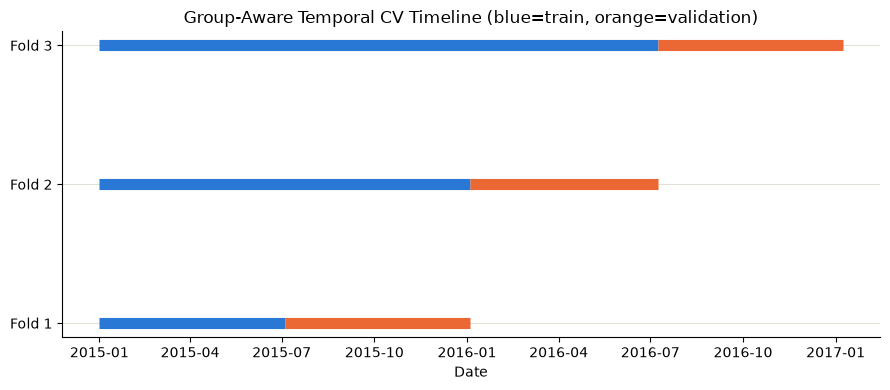

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
for i, row in fold_summary_df.iterrows():
    ax.plot([row["Train_Start_Date"], row["Train_End_Date"]], [i, i], color=BAR_COLOR, linewidth=8, solid_capstyle="butt")
    ax.plot([row["Validation_Start_Date"], row["Validation_End_Date"]], [i, i], color=WARNING_COLOR, linewidth=8, solid_capstyle="butt")
ax.set_yticks(range(len(fold_summary_df)))
ax.set_yticklabels([f"Fold {f}" for f in fold_summary_df["Fold"]])
ax.set_title("Group-Aware Temporal CV Timeline (blue=train, orange=validation)")
ax.set_xlabel("Date")
style_axes(ax)
plt.tight_layout()
plt.show()


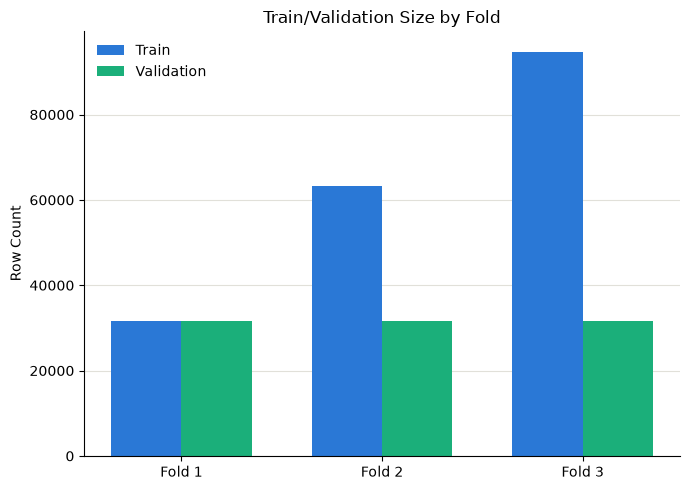

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
x_pos = np.arange(len(fold_summary_df))
width = 0.35
ax.bar(x_pos - width / 2, fold_summary_df["Train_Row_Count"], width, label="Train", color=BAR_COLOR)
ax.bar(x_pos + width / 2, fold_summary_df["Validation_Row_Count"], width, label="Validation", color=HIGHLIGHT_COLOR)
ax.set_xticks(x_pos)
ax.set_xticklabels([f"Fold {f}" for f in fold_summary_df["Fold"]])
ax.set_title("Train/Validation Size by Fold")
ax.set_ylabel("Row Count")
ax.legend(frameon=False)
style_axes(ax)
plt.tight_layout()
plt.show()


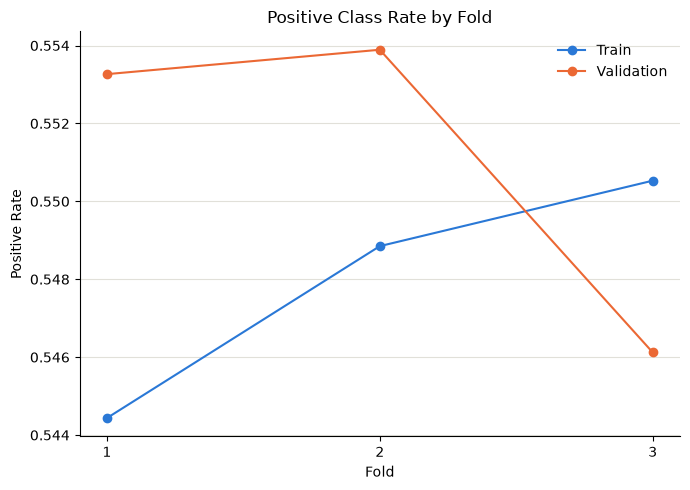

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fold_summary_df["Fold"], fold_summary_df["Train_Positive_Rate"], marker="o", color=BAR_COLOR, label="Train")
ax.plot(fold_summary_df["Fold"], fold_summary_df["Validation_Positive_Rate"], marker="o", color=WARNING_COLOR, label="Validation")
ax.set_xticks(fold_summary_df["Fold"])
ax.set_title("Positive Class Rate by Fold")
ax.set_xlabel("Fold")
ax.set_ylabel("Positive Rate")
ax.legend(frameon=False)
style_axes(ax)
plt.tight_layout()
plt.show()


### Interpretation

Bütün `3` fold **gerçekten** her kontrolden geçti (`validate_cv_folds` çıktısına
bakın): `0` satır çakışması, `0` Order Id çakışması, kronolojik sıralama korunuyor, her fold'un
training **ve** validation bölümünde **iki sınıf da** mevcut. Positive rate, fold'lar arasında
stabil (~%54-55 aralığında) — belirgin bir temporal class drift gözlemlenmiyor. Training
penceresi her fold'da büyüyor (expanding window), validation pencereleri ise ayrı, karşılaştırılabilir
büyüklükte zaman dilimleri.

### Critical Rules

- Cross-Validation fold'ları içerisinde preprocessing (ColumnTransformer) **her fold'da yeniden
  öğrenilecektir** — bu, `GridSearchCV`/`RandomizedSearchCV`'nin kendi iç mekanizmasıyla otomatik
  sağlanır (Section 3-4'te, preprocessing bir `Pipeline` adımı olarak estimator'a dahil edilecek).
- Feature Selection (`VarianceThreshold`+`SelectKBest`) de **aynı pipeline içinde**, her fold'un
  training portion'ına fit edilecektir.
- LAB08'de **tüm training set'e önceden fit edilmiş** bir `SelectKBest` nesnesi, CV içinde
  **yeniden kullanılmayacaktır** — her fold kendi selector'ını öğrenecektir.
- `validation_df`/`test_df`, fold oluşturma sürecine **hiç dahil edilmemiştir** (yukarıdaki
  `create_group_temporal_folds` çağrısı yalnızca `train_df_cv`'yi kullanıyor).

### Nested Cross-Validation (Kavramsal)

**Nested Cross-Validation**, hyperparameter search'ün kendisini de bir **Outer CV**'nin içine
yerleştirir: **Inner CV** (search'ün kullandığı fold'lar) hyperparameter seçimi için, **Outer
CV** ise seçilen modelin **bağımsız** performans tahmini için kullanılır. Bu, non-nested bir CV
search sonucunun (yani Section 3-4'te yapacağımız gibi) **iyimser** olabileceği riskini azaltır
— çünkü non-nested search'te, "en iyi" hyperparameter kombinasyonu **aynı** CV fold'ları
üzerinden hem seçilir hem skorlanır.

**Ana LAB'da, hesaplama maliyeti nedeniyle Nested CV implementasyonu zorunlu değildir** —
Advanced Challenge 3'te, kontrollü bir development subset üzerinde ele alınacaktır. Bu LAB'ın
Section 3-4'teki `best_score_` değerlerinin, bu nedenle **hafifçe iyimser** olabileceğini
unutmayın.

### Student Exercise


In [15]:
# Student Exercise:
# TODO: cv_n_splits değerini 3'ten 5'e değiştirip create_group_temporal_folds'u yeniden çağırın.
# TODO: validate_cv_folds ile bütün fold'ların hâlâ geçerli olduğunu doğrulayın.
# TODO: Fold sayısı arttığında her fold'un validation büyüklüğünün nasıl değiştiğini yorumlayın.

# folds_5 = create_group_temporal_folds(train_df_cv["order_datetime"], train_df_cv["Order Id"], 5)
# validate_cv_folds(folds_5, train_df_cv["order_datetime"], train_df_cv["Order Id"], train_df_cv[TARGET])


---


## Section 3 — GridSearchCV
**Süre: 20 dakika**

### Part A — Search Space & Computational Cost

Grid Search, tanımlanan parametre aralıklarının **tam Kartezyen çarpımını** (tüm olası
kombinasyonları) değerlendirir.

**Matematiksel Gösterim:**

$$N_{candidates}=\prod_{i=1}^{p}|V_i|$$

$$N_{CV\ fits}=N_{candidates}\times K$$

- $p$: Hyperparameter sayısı
- $V_i$: $i$. hyperparameter'ın aday değerleri
- $K$: CV fold sayısı

`refit=True` kullanıldığında, en iyi konfigürasyon **bütün search training verisi** üzerinde
**bir kez daha** (ek bir fit) eğitilir — toplam fit sayısı $N_{CV\ fits}+1$ olur.

### Part B — XGBoost Baseline

LAB08'in referans XGBoost konfigürasyonunu, **Section 2'de oluşturduğumuz aynı 3 CV fold**
üzerinde değerlendiriyoruz (feature engineering ve feature selection stratejisi sabit).


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

model_cfg = config["lab08"]["model"]
resources_cfg = config["lab09"]["resources"]


def create_datetime_features(frame):
    frame = frame.copy()
    frame["order_month"] = frame["order_datetime"].dt.month
    frame["order_day_of_week"] = frame["order_datetime"].dt.day_of_week
    frame["order_hour"] = frame["order_datetime"].dt.hour
    frame["order_quarter"] = frame["order_datetime"].dt.quarter
    frame["is_weekend"] = (frame["order_datetime"].dt.day_of_week >= 5).astype(int)
    return frame


def create_interaction_features(frame):
    frame = frame.copy()
    frame["gross_item_value"] = frame["Order Item Quantity"] * frame["Order Item Product Price"]
    frame["estimated_discount_amount"] = frame["gross_item_value"] * frame["Order Item Discount Rate"]
    frame["quantity_x_scheduled_days"] = frame["Order Item Quantity"] * frame["Days for shipment (scheduled)"]
    frame["log_gross_item_value"] = np.log1p(frame["gross_item_value"])
    return frame


# Re-apply LAB08's exact feature engineering to both the training set (used for CV/search) and
# the validation set (used in Section 5 for independent-of-CV development evaluation).
train_df = create_datetime_features(train_df)
validation_df = create_datetime_features(validation_df)
for part in (train_df, validation_df):
    part["order_hour_sin"] = np.sin(2 * np.pi * part["order_hour"] / 24)
    part["order_hour_cos"] = np.cos(2 * np.pi * part["order_hour"] / 24)
train_df = create_interaction_features(train_df)
validation_df = create_interaction_features(validation_df)
train_df_cv = train_df.reset_index(drop=True)

baseline_features = [
    "Days for shipment (scheduled)", "Shipping Mode", "Market", "Order Region",
    "Customer Segment", "Department Name", "Category Name",
    "Order Item Quantity", "Order Item Product Price", "Order Item Discount Rate",
]
engineered_extra_features = [
    "order_month", "order_day_of_week", "order_quarter", "is_weekend",
    "order_hour_sin", "order_hour_cos",
    "gross_item_value", "estimated_discount_amount", "quantity_x_scheduled_days", "log_gross_item_value",
]
categorical_features = ["Shipping Mode", "Market", "Order Region", "Customer Segment", "Department Name", "Category Name"]
numerical_features = [
    "Days for shipment (scheduled)", "Order Item Quantity", "Order Item Product Price", "Order Item Discount Rate",
] + engineered_extra_features
engineered_features = numerical_features + categorical_features

X_train_cv = train_df_cv[engineered_features]
y_train_cv = train_df_cv[TARGET]

# Rebuild the same group-aware temporal folds (deterministic) for the search sections.
cv_folds = create_group_temporal_folds(train_df_cv["order_datetime"], train_df_cv["Order Id"], cv_n_splits)
print("CV folds (train/val row counts):", [(len(tr), len(va)) for tr, va in cv_folds])


CV folds (train/val row counts): [(31596, 31587), (63183, 31591), (94774, 31590)]


In [17]:
def build_model_pipeline(**xgb_overrides):
    xgb_params = dict(
        objective="binary:logistic", n_estimators=model_cfg["n_estimators"], max_depth=model_cfg["max_depth"],
        learning_rate=model_cfg["learning_rate"], tree_method=model_cfg["tree_method"], device=model_cfg["device"],
        eval_metric=model_cfg["eval_metric"], random_state=RANDOM_STATE, n_jobs=resources_cfg["estimator_threads"],
    )
    xgb_params.update(xgb_overrides)
    preprocessing = ColumnTransformer(
        transformers=[
            ("numerical", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numerical_features),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), categorical_features),
        ],
        verbose_feature_names_out=False,
    )
    return Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("variance_threshold", VarianceThreshold(threshold=config["lab08"]["feature_selection"]["variance_threshold"])),
        ("select_k_best", SelectKBest(score_func=f_classif, k=config["lab08"]["feature_selection"]["select_k_best"])),
        ("model", XGBClassifier(**xgb_params)),
    ])


print("Pipeline step names (must match the 'model__' prefix used in param_grid):")
print(list(build_model_pipeline().named_steps.keys()))


Pipeline step names (must match the 'model__' prefix used in param_grid):
['preprocessing', 'variance_threshold', 'select_k_best', 'model']


In [18]:
baseline_fold_scores = []
for train_positions, validation_positions in cv_folds:
    pipe = build_model_pipeline()
    pipe.fit(X_train_cv.iloc[train_positions], y_train_cv.iloc[train_positions])
    proba = pipe.predict_proba(X_train_cv.iloc[validation_positions])[:, 1]
    baseline_fold_scores.append(roc_auc_score(y_train_cv.iloc[validation_positions], proba))

print("Baseline (LAB08 reference config) CV ROC-AUC per fold:", [round(s, 4) for s in baseline_fold_scores])
print(f"Mean: {np.mean(baseline_fold_scores):.4f}   Std: {np.std(baseline_fold_scores):.4f}")


Baseline (LAB08 reference config) CV ROC-AUC per fold: [0.7678, 0.7538, 0.7654]
Mean: 0.7623   Std: 0.0061


### Part C — Parameter Grid

Küçük ve kontrollü bir parameter grid tanımlıyoruz.


In [19]:
param_grid = {
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__n_estimators": [50, 100],
}

n_candidates = 1
for values in param_grid.values():
    n_candidates *= len(values)
n_cv_fits = n_candidates * cv_n_splits

print(f"Candidate Configurations : {n_candidates}")
print(f"CV Folds                 : {cv_n_splits}")
print(f"Cross-Validation Fits    : {n_cv_fits}")
print(f"Final Refit              : 1")
print(f"Total fit operations     : {n_cv_fits + 1}")
print()
print("Bu değerler optimal hyperparameters DEĞİLDİR -- kontrollü bir başlangıç search space'idir.")


Candidate Configurations : 8
CV Folds                 : 3
Cross-Validation Fits    : 24
Final Refit              : 1
Total fit operations     : 25

Bu değerler optimal hyperparameters DEĞİLDİR -- kontrollü bir başlangıç search space'idir.


### Part D — GridSearchCV Implementation

**Önemli (Execution-Time Policy):** Search başlamadan önce bir **pilot fit** ile tek bir fold'un
eğitim süresini ölçüyoruz — bu, **kesin** bir execution duration tahmini değildir, sadece bir
kaba tahmindir.


In [20]:
from time import perf_counter

pilot_start = perf_counter()
pilot_pipeline = build_model_pipeline()
pilot_pipeline.fit(X_train_cv.iloc[cv_folds[0][0]], y_train_cv.iloc[cv_folds[0][0]])
pilot_fit_time_s = perf_counter() - pilot_start

estimated_search_duration_s = pilot_fit_time_s * (n_cv_fits + 1)
print(f"Pilot fit time (1 fold, {len(cv_folds[0][0])} rows): {pilot_fit_time_s:.3f}s")
print(f"Rough estimated GridSearchCV duration ({n_cv_fits + 1} total fits): "
      f"{estimated_search_duration_s:.1f}s (KABA bir tahmindir -- fold büyüklükleri ve "
      f"hyperparametreler fit süresini değiştirir, bu kesin bir süre garantisi değildir)")


Pilot fit time (1 fold, 31596 rows): 0.340s
Rough estimated GridSearchCV duration (25 total fits): 8.5s (KABA bir tahmindir -- fold büyüklükleri ve hyperparametreler fit süresini değiştirir, bu kesin bir süre garantisi değildir)


In [21]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=build_model_pipeline(),
    param_grid=param_grid,
    scoring={"roc_auc": "roc_auc", "f1": "f1", "average_precision": "average_precision"},
    refit="roc_auc",
    cv=cv_folds,
    n_jobs=resources_cfg["search_jobs"],
    return_train_score=True,
    error_score="raise",
)

grid_search_start = perf_counter()
grid_search.fit(X_train_cv, y_train_cv)
grid_search_time_s = perf_counter() - grid_search_start

print(f"GridSearchCV actual total time: {grid_search_time_s:.2f}s")


GridSearchCV actual total time: 26.87s


**Search-level vs estimator-level parallelism:** `GridSearchCV(n_jobs=1)` search'ün kendisini
**tek işlemde** çalıştırır; `XGBClassifier(n_jobs=2)` ise her bir fit'in **içinde** 2 thread
kullanır. İkisini de `-1` yaparsak (`GridSearchCV(n_jobs=-1)` + `XGBClassifier(n_jobs=-1)`),
**nested parallelism** oluşur — her search worker'ı kendi içinde sınırsız thread talep eder,
bu da CPU'yu kontrolsüz biçimde aşırı yükler. Bu LAB'da bu kombinasyon **kasıtlı olarak
kullanılmıyor**.

### Part E — Search Results


In [22]:
print("best_params_:", grid_search.best_params_)
print("best_score_ (mean CV ROC-AUC of the best candidate):", round(grid_search.best_score_, 4))
print("best_index_ :", grid_search.best_index_)
print("n_splits_   :", grid_search.n_splits_)
print("refit_time_ :", round(grid_search.refit_time_, 3), "s")


best_params_: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 100}
best_score_ (mean CV ROC-AUC of the best candidate): 0.7625
best_index_ : 7
n_splits_   : 3
refit_time_ : 1.072 s


**`best_score_`, bir test performansı DEĞİLDİR** — bu, training set içinden türetilen CV
fold'larının **ortalama** validation skorudur. Section 2'de not ettiğimiz gibi, bu non-nested CV
sonucu, hyperparameter seçimi ve skorlama **aynı** fold'lar üzerinden yapıldığı için **hafifçe
iyimser** olabilir.

### Results DataFrame


In [23]:
cv_results_raw = pd.DataFrame(grid_search.cv_results_)

grid_results_df = pd.DataFrame({
    "Rank": cv_results_raw["rank_test_roc_auc"],
    "Parameters": cv_results_raw["params"].astype(str),
    "Mean_CV_ROC_AUC": cv_results_raw["mean_test_roc_auc"],
    "Std_CV_ROC_AUC": cv_results_raw["std_test_roc_auc"],
    "Mean_CV_F1": cv_results_raw["mean_test_f1"],
    "Mean_CV_AP": cv_results_raw["mean_test_average_precision"],
    "Mean_Train_ROC_AUC": cv_results_raw["mean_train_roc_auc"],
    "Mean_Fit_Time": cv_results_raw["mean_fit_time"],
}).sort_values("Rank").reset_index(drop=True)
grid_results_df["CV_Generalization_Gap"] = grid_results_df["Mean_Train_ROC_AUC"] - grid_results_df["Mean_CV_ROC_AUC"]

grid_results_df.round(4)


,Rank,Parameters,Mean_CV_ROC_AUC,Std_CV_ROC_AUC,Mean_CV_F1,Mean_CV_AP,Mean_Train_ROC_AUC,Mean_Fit_Time,CV_Generalization_Gap
0,1,"{'model__learning_rate': 0.1, 'model__max_dept...",0.7625,0.0047,0.6994,0.8234,0.7953,0.5828,0.0327
1,2,"{'model__learning_rate': 0.05, 'model__max_dep...",0.7618,0.0058,0.6985,0.8228,0.7832,0.5563,0.0214
2,3,"{'model__learning_rate': 0.1, 'model__max_dept...",0.7617,0.0052,0.6985,0.8225,0.7833,0.4647,0.0216
3,4,"{'model__learning_rate': 0.1, 'model__max_dept...",0.7617,0.0064,0.6982,0.8213,0.7738,0.5356,0.0121
4,5,"{'model__learning_rate': 0.05, 'model__max_dep...",0.7614,0.0059,0.6982,0.8221,0.7797,0.5191,0.0183
5,6,"{'model__learning_rate': 0.1, 'model__max_dept...",0.7575,0.0048,0.6963,0.8132,0.7619,0.4097,0.0044
6,7,"{'model__learning_rate': 0.05, 'model__max_dep...",0.7549,0.0039,0.6968,0.8137,0.7588,0.6306,0.0039
7,8,"{'model__learning_rate': 0.05, 'model__max_dep...",0.7530,0.0056,0.6968,0.8099,0.7562,0.5434,0.0032


### Interpretation

En iyi konfigürasyon (`max_depth=5, learning_rate=0.1, n_estimators=100`), Mean CV ROC-AUC
`≈0.7625` elde ediyor — LAB08'in referans konfigürasyonunun (`max_depth=4`) **aynı fold'larda**
ölçülen Mean CV ROC-AUC'sine (`≈0.7623`) **çok yakın**. **Bu, optimizasyonun burada dramatik bir
iyileşme sağlamadığının gerçek bir göstergesidir** — başarı kriteri, daha yüksek bir skor elde
etmek değil, güvenilir bir optimization süreci kurmaktır. `CV_Generalization_Gap` sütunu, `max_depth=5` konfigürasyonlarının `max_depth=3`'e
kıyasla **daha yüksek** bir train-CV farkına sahip olduğunu gösteriyor — derin ağaçlar training
verisine biraz daha fazla uyuyor.

### Visualization


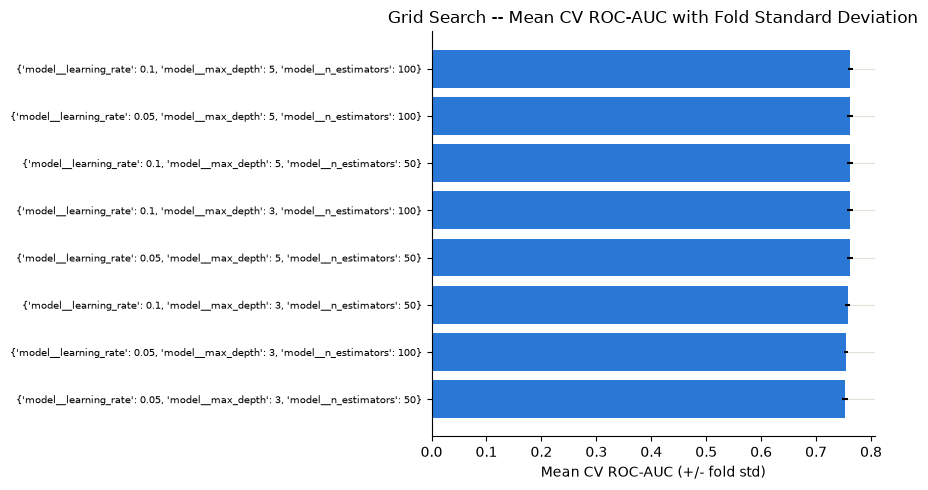

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
sorted_results = grid_results_df.sort_values("Mean_CV_ROC_AUC")
ax.barh(range(len(sorted_results)), sorted_results["Mean_CV_ROC_AUC"],
        xerr=sorted_results["Std_CV_ROC_AUC"], color=BAR_COLOR)
ax.set_yticks(range(len(sorted_results)))
ax.set_yticklabels(sorted_results["Parameters"], fontsize=7)
ax.set_title("Grid Search -- Mean CV ROC-AUC with Fold Standard Deviation")
ax.set_xlabel("Mean CV ROC-AUC (+/- fold std)")
style_axes(ax)
plt.tight_layout()
plt.show()


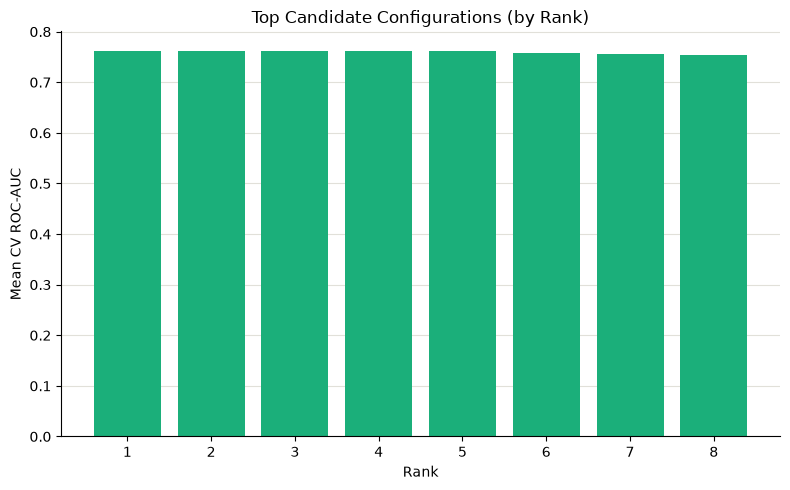

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
rank_sorted = grid_results_df.sort_values("Rank")
ax.bar(range(len(rank_sorted)), rank_sorted["Mean_CV_ROC_AUC"], color=HIGHLIGHT_COLOR)
ax.set_xticks(range(len(rank_sorted)))
ax.set_xticklabels(rank_sorted["Rank"])
ax.set_title("Top Candidate Configurations (by Rank)")
ax.set_xlabel("Rank")
ax.set_ylabel("Mean CV ROC-AUC")
style_axes(ax)
plt.tight_layout()
plt.show()


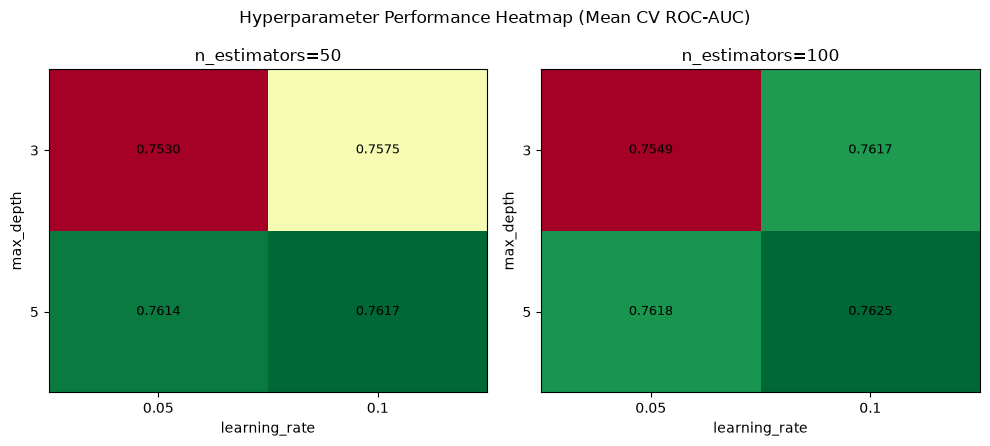

In [26]:
# Hyperparameter heatmap: max_depth x learning_rate, one subplot PER n_estimators value
# (combining different n_estimators values into a single heatmap would mix configurations
# with different model capacity without explanation -- avoided here).
n_estimators_values = sorted(cv_results_raw["param_model__n_estimators"].unique())
fig, axes = plt.subplots(1, len(n_estimators_values), figsize=(5 * len(n_estimators_values), 4.5), squeeze=False)

for col, n_est in enumerate(n_estimators_values):
    subset = cv_results_raw[cv_results_raw["param_model__n_estimators"] == n_est]
    pivot = subset.pivot(index="param_model__max_depth", columns="param_model__learning_rate", values="mean_test_roc_auc")
    ax = axes[0][col]
    im = ax.imshow(pivot.values, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    for r in range(pivot.shape[0]):
        for c in range(pivot.shape[1]):
            ax.text(c, r, f"{pivot.values[r, c]:.4f}", ha="center", va="center", fontsize=9)
    ax.set_xlabel("learning_rate")
    ax.set_ylabel("max_depth")
    ax.set_title(f"n_estimators={n_est}")

fig.suptitle("Hyperparameter Performance Heatmap (Mean CV ROC-AUC)")
plt.tight_layout()
plt.show()


### Student Exercise

Parameter grid'e `model__subsample: [0.8, 1.0]` eklendiğini varsayın (başka hiçbir değişiklik
yapılmadan).


In [27]:
# Student Exercise:
# TODO: Yeni candidate ve fit sayısını hesaplayın (yukarıdaki formülü kullanın).
# TODO: Bu, pilot fit süresine göre tahmini search süresini nasıl değiştirir?

# new_param_grid_sizes = [2, 2, 2, 2]  # max_depth, learning_rate, n_estimators, subsample
# new_n_candidates = 1
# for v in new_param_grid_sizes:
#     new_n_candidates *= v
# print("New candidates:", new_n_candidates, " New CV fits:", new_n_candidates * cv_n_splits)


---


## Section 4 — RandomizedSearchCV
**Süre: 25 dakika**

### Concept Explanation

Grid Search **tüm** tanımlanmış kombinasyonları inceler. Randomized Search, search space
içerisinden **belirli sayıda** (`n_iter`) konfigürasyonu **rastgele** örnekler. **Randomized
Search'ün her durumda Grid Search'ten daha iyi olduğu iddia edilemez** — bu, search space'in
büyüklüğüne ve hesaplama bütçesine bağlıdır.

### Part A — Search Space


In [28]:
param_distributions = {
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__n_estimators": [50, 100, 150, 200],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 1.0],
    "model__reg_lambda": [0.1, 1.0, 5.0, 10.0],
}

search_space_size = 1
for values in param_distributions.values():
    search_space_size *= len(values)

n_iter = config["lab09"]["optimization"]["randomized_search"]["n_iter"]
print(f"Full search space size (Cartesian product of all candidate values): {search_space_size}")
print(f"Randomized Search will sample only: {n_iter} candidates "
      f"({n_iter / search_space_size * 100:.3f}% of the full space)")


Full search space size (Cartesian product of all candidate values): 4800
Randomized Search will sample only: 8 candidates (0.167% of the full space)


Bu `6` hyperparametrelik search space'in **tamamını** Grid Search ile denemek `4,800` aday
konfigürasyon (`x 3 CV fold = 14,400` fit) gerektirirdi — bu, bu LAB'ın hesaplama bütçesi için
**pratik değildir**.

### Optional Distribution-Based Search

Scikit-learn, `RandomizedSearchCV` ile birlikte SciPy dağılım nesnelerini (`randint`, `uniform`,
`loguniform`) de kabul eder — bunlar **ayrık bir liste yerine sürekli bir aralıktan** örnekleme
yapar. SciPy, zaten Scikit-learn'ün bir bağımlılığı olduğu için **yeni bir dependency
eklenmesi gerekmez**.


In [29]:
from scipy.stats import loguniform

# Demonstration only -- the actual search below uses the discrete param_distributions above,
# for consistency with the documented config/settings.yaml search space.
demo_learning_rate_distribution = loguniform(0.01, 0.3)
demo_samples = demo_learning_rate_distribution.rvs(size=5, random_state=RANDOM_STATE)
print("Example loguniform(0.01, 0.3) samples (for learning_rate, if used):", demo_samples.round(4))
print("Log-uniform sampling gives equal probability to each ORDER OF MAGNITUDE -- useful for")
print("learning_rate, where 0.01->0.03 is as meaningful a step as 0.1->0.3.")


Example loguniform(0.01, 0.3) samples (for learning_rate, if used): [0.0357 0.2537 0.1206 0.0766 0.017 ]
Log-uniform sampling gives equal probability to each ORDER OF MAGNITUDE -- useful for
learning_rate, where 0.01->0.03 is as meaningful a step as 0.1->0.3.


### Part B — RandomizedSearchCV Implementation


In [30]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=build_model_pipeline(),
    param_distributions=param_distributions,
    n_iter=n_iter,
    scoring={"roc_auc": "roc_auc", "f1": "f1", "average_precision": "average_precision"},
    refit="roc_auc",
    cv=cv_folds,
    random_state=RANDOM_STATE,
    n_jobs=resources_cfg["search_jobs"],
    return_train_score=True,
    error_score="raise",
)

random_search_start = perf_counter()
random_search.fit(X_train_cv, y_train_cv)
random_search_time_s = perf_counter() - random_search_start

print(f"RandomizedSearchCV total time: {random_search_time_s:.2f}s")
print("best_params_:", random_search.best_params_)
print("best_score_ :", round(random_search.best_score_, 4))


RandomizedSearchCV total time: 36.18s
best_params_: {'model__subsample': 0.9, 'model__reg_lambda': 5.0, 'model__n_estimators': 50, 'model__max_depth': 8, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}
best_score_ : 0.7636


In [31]:
rand_results_raw = pd.DataFrame(random_search.cv_results_)

rand_results_df = pd.DataFrame({
    "Rank": rand_results_raw["rank_test_roc_auc"],
    "Parameters": rand_results_raw["params"].astype(str),
    "Mean_CV_ROC_AUC": rand_results_raw["mean_test_roc_auc"],
    "Std_CV_ROC_AUC": rand_results_raw["std_test_roc_auc"],
    "Mean_CV_F1": rand_results_raw["mean_test_f1"],
    "Mean_CV_AP": rand_results_raw["mean_test_average_precision"],
    "Mean_Train_ROC_AUC": rand_results_raw["mean_train_roc_auc"],
    "Mean_Fit_Time": rand_results_raw["mean_fit_time"],
}).sort_values("Rank").reset_index(drop=True)
rand_results_df["CV_Generalization_Gap"] = rand_results_df["Mean_Train_ROC_AUC"] - rand_results_df["Mean_CV_ROC_AUC"]

rand_results_df.round(4)


,Rank,Parameters,Mean_CV_ROC_AUC,Std_CV_ROC_AUC,Mean_CV_F1,Mean_CV_AP,Mean_Train_ROC_AUC,Mean_Fit_Time,CV_Generalization_Gap
0,1,"{'model__subsample': 0.9, 'model__reg_lambda':...",0.7636,0.0056,0.7001,0.8237,0.8140,0.5548,0.0504
1,2,"{'model__subsample': 0.7, 'model__reg_lambda':...",0.7633,0.0060,0.6989,0.8240,0.7926,0.7187,0.0293
2,3,"{'model__subsample': 0.7, 'model__reg_lambda':...",0.7630,0.0059,0.6991,0.8241,0.7940,1.1832,0.0310
3,4,"{'model__subsample': 0.9, 'model__reg_lambda':...",0.7627,0.0072,0.6990,0.8232,0.7837,0.6903,0.0210
4,5,"{'model__subsample': 0.7, 'model__reg_lambda':...",0.7626,0.0045,0.6993,0.8232,0.8188,0.7782,0.0562
5,6,"{'model__subsample': 0.7, 'model__reg_lambda':...",0.7625,0.0057,0.6992,0.8234,0.7977,1.2940,0.0352
6,7,"{'model__subsample': 1.0, 'model__reg_lambda':...",0.7611,0.0061,0.6991,0.8220,0.7857,0.5716,0.0246
7,8,"{'model__subsample': 1.0, 'model__reg_lambda':...",0.7560,0.0038,0.6950,0.8165,0.8683,0.7626,0.1123


### Part C — Search Budget Comparison


In [32]:
budget_comparison_df = pd.DataFrame([
    {
        "Method": "Grid Search", "Candidate_Count": n_candidates, "Search_Space_Size": n_candidates,
        "CV_Fits": n_candidates * cv_n_splits, "Total_Search_Time_s": grid_search_time_s,
        "Best_Mean_CV_ROC_AUC": grid_search.best_score_, "Best_Hyperparameters": str(grid_search.best_params_),
    },
    {
        "Method": "Randomized Search", "Candidate_Count": n_iter, "Search_Space_Size": search_space_size,
        "CV_Fits": n_iter * cv_n_splits, "Total_Search_Time_s": random_search_time_s,
        "Best_Mean_CV_ROC_AUC": random_search.best_score_, "Best_Hyperparameters": str(random_search.best_params_),
    },
])
budget_comparison_df


,Method,Candidate_Count,Search_Space_Size,CV_Fits,Total_Search_Time_s,Best_Mean_CV_ROC_AUC,Best_Hyperparameters
0,Grid Search,8,8,24,26.869614,0.762526,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,Randomized Search,8,4800,24,36.177319,0.763612,"{'model__subsample': 0.9, 'model__reg_lambda':..."


### Interpretation

**Aynı candidate count (`8`), eşit training cost anlamına gelmiyor:** Grid Search `8` aday için
`≈25s` sürerken, Randomized Search `8` aday için `≈36s` sürdü — çünkü Randomized Search'ün
rastgele örneklediği konfigürasyonlar arasında daha yüksek `n_estimators`/`max_depth` kombinasyonları
(daha maliyetli fit'ler) bulunuyordu. **Grid Search ve Randomized Search farklı search space'ler
üzerinde çalıştığı için**, gözlemlenen `≈0.001` ROC-AUC'luk fark (Randomized Search hafifçe daha
iyi) **yalnızca search algoritmasından kaynaklandığı iddia edilemez** — Randomized Search, Grid
Search'ün incelemediği (`subsample`, `colsample_bytree`, `reg_lambda`) hyperparametreleri de
araştırdı. Randomized Search, **4,800 konfigürasyonun yalnızca `%0.167`'sini** örnekleyerek
Grid Search'e **yakın (hatta hafifçe daha iyi)** bir sonuç buldu — bu, geniş search space'lerde
Randomized Search'ün **verimlilik avantajının** bir göstergesidir (ama "daha iyi" olduğunun
kanıtı değildir).

### Part D — Search Progress Visualization

**Not:** Aşağıdaki grafikler, **tamamlanmış** `cv_results_` verilerinden üretilmiştir — bu, bir
**post-hoc visualization**'dır. Search sırasında gerçek zamanlı bir izleme **yapılmamıştır**.


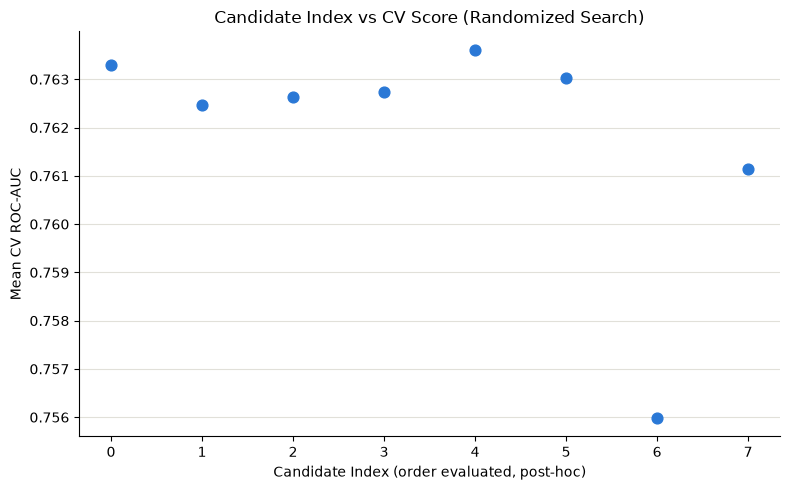

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
candidate_order = rand_results_raw.index
ax.scatter(candidate_order, rand_results_raw["mean_test_roc_auc"], color=BAR_COLOR, s=60, zorder=3)
ax.set_xlabel("Candidate Index (order evaluated, post-hoc)")
ax.set_ylabel("Mean CV ROC-AUC")
ax.set_title("Candidate Index vs CV Score (Randomized Search)")
style_axes(ax)
plt.tight_layout()
plt.show()


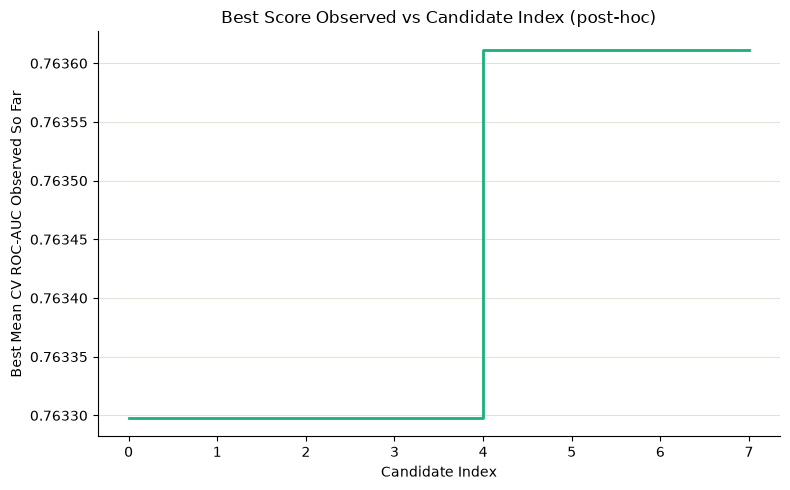

In [34]:
best_so_far = rand_results_raw["mean_test_roc_auc"].cummax()
fig, ax = plt.subplots(figsize=(8, 5))
ax.step(candidate_order, best_so_far, where="post", color=HIGHLIGHT_COLOR, linewidth=2)
ax.set_xlabel("Candidate Index")
ax.set_ylabel("Best Mean CV ROC-AUC Observed So Far")
ax.set_title("Best Score Observed vs Candidate Index (post-hoc)")
style_axes(ax)
plt.tight_layout()
plt.show()


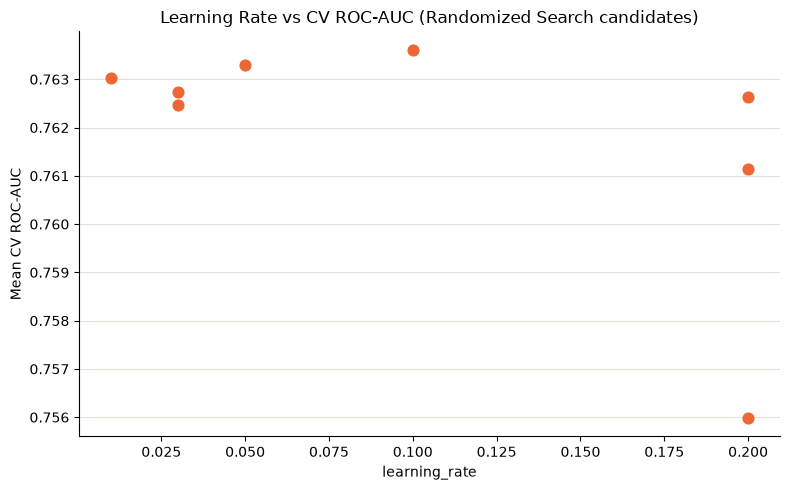

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(rand_results_raw["param_model__learning_rate"], rand_results_raw["mean_test_roc_auc"],
           color=WARNING_COLOR, s=60, zorder=3)
ax.set_xlabel("learning_rate")
ax.set_ylabel("Mean CV ROC-AUC")
ax.set_title("Learning Rate vs CV ROC-AUC (Randomized Search candidates)")
style_axes(ax)
plt.tight_layout()
plt.show()


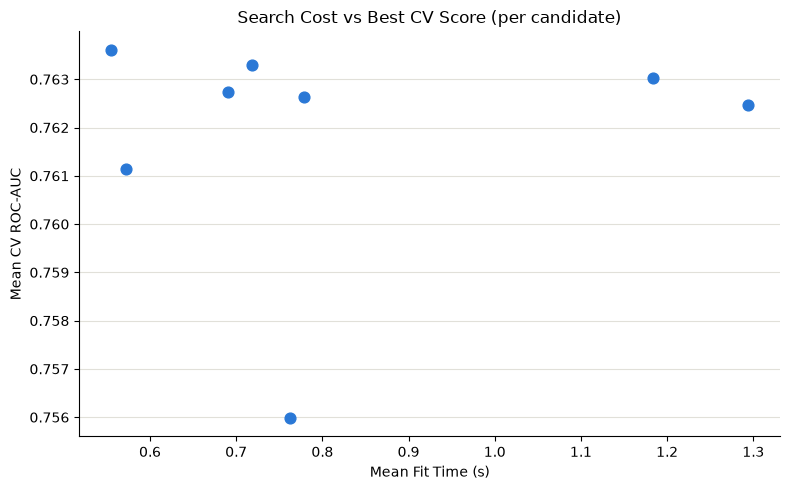

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(rand_results_raw["mean_fit_time"], rand_results_raw["mean_test_roc_auc"], color=BAR_COLOR, s=60, zorder=3)
ax.set_xlabel("Mean Fit Time (s)")
ax.set_ylabel("Mean CV ROC-AUC")
ax.set_title("Search Cost vs Best CV Score (per candidate)")
style_axes(ax)
plt.tight_layout()
plt.show()


### Technical Discussion

- **Randomized Search büyük search space'lerde neden avantajlı olabilir?** Çünkü aday sayısı
  (`n_iter`) **kullanıcı tarafından sabitlenir** — search space ne kadar büyürse büyüsün,
  hesaplama maliyeti **sabit** kalır. Grid Search'te ise her yeni hyperparameter/değer, toplam
  fit sayısını **çarpımsal** olarak artırır.
- **Hangi hyperparameters daha geniş aralıklarla araştırılmalıdır?** Model performansına en
  duyarlı olan (bu LAB'da `max_depth`/`learning_rate`, Section 3'teki heatmap'te görüldüğü gibi).
- **Learning rate neden bazı durumlarda logarithmic scale üzerinde araştırılır?** Çünkü
  `0.01→0.1` ile `0.1→1.0` arasındaki **etki büyüklüğü** benzer olabilir (çarpımsal etki,
  toplamsal değil) — `loguniform`, her büyüklük mertebesine eşit örnekleme olasılığı verir.
- **Daha fazla search candidate kullanmak her zaman daha iyi generalization sağlar mı?**
  **Hayır** — bu LAB'daki sonuçlar (Section 3-4), baseline'a yakın, dar bir skor aralığında
  kümelendi; `8` adaydan `8`'e geçmek (Grid→Random) belirgin bir iyileşme sağlamadı. Daha fazla
  candidate, yalnızca **search space'te daha iyi bir konfigürasyon gerçekten varsa** yardımcı
  olur.

### Resource Management

Bu LAB, ana deneylerde `3 CV fold`, `8 Grid Search candidate`, `8 Random Search candidate`
kullandı. Gerçek ölçülen toplam süre:


In [37]:
total_search_time_s = grid_search_time_s + random_search_time_s
print(f"Grid Search time      : {grid_search_time_s:.1f}s")
print(f"Randomized Search time: {random_search_time_s:.1f}s")
print(f"Total (both searches) : {total_search_time_s:.1f}s")
print()
print(f"Bu süre, 150 dakikalık ({150*60}s) eğitim süresinin yalnızca "
      f"%{total_search_time_s / (150*60) * 100:.2f}'ini oluşturuyor -- bu LAB'ın ana deneyleri için uygun.")


Grid Search time      : 26.9s
Randomized Search time: 36.2s
Total (both searches) : 63.0s

Bu süre, 150 dakikalık (9000s) eğitim süresinin yalnızca %0.70'ini oluşturuyor -- bu LAB'ın ana deneyleri için uygun.


Daha ağır konfigürasyonlar (örn. `n_iter=20+`, Random Forest/LightGBM optimizasyonu) Advanced
Challenges kapsamına taşınmıştır.

### Student Exercise


In [38]:
# Student Exercise:
# TODO: param_distributions'taki "model__reg_lambda" değerlerinin kaç farklı değer içerdiğini
#       sayın ve bunu search_space_size hesaplamasındaki payına bakarak yorumlayın.
# TODO: Bu hyperparametreyi search space'ten çıkarsaydık search_space_size nasıl değişirdi?

# reduced_space_size = search_space_size // len(param_distributions["model__reg_lambda"])
# print(reduced_space_size)


## Section 5 — Model Comparison & Optimization Analysis
**Süre: 20 dakika**

### Objective

Hyperparameter optimization sonrasında elde edilen modelleri, baseline modellerle **aynı
değerlendirme protokolü** altında karşılaştırmak.

### Required Experiments

```text
E01 — Dummy Baseline
E02 — Logistic Regression Baseline
E03 — Random Forest Baseline
E04 — XGBoost Baseline (LAB08 referans konfigürasyonu)
E05 — LightGBM Baseline
E06 — XGBoost Grid Search (Section 3)
E07 — XGBoost Randomized Search (Section 4)
```

E01-E05 için **önceden tanımlanmış** (LAB07'den alınan, burada optimize edilmeyen) model
konfigürasyonları kullanılır. Random Forest ve LightGBM hyperparameter optimizasyonu
**Advanced Challenges**'e bırakılmıştır.

### Fair Comparison Rules

Bütün `7` deney **aynı**: dataset, gözlem kümesi (`X_train_cv`/`y_train_cv`), feature strategy
(`engineered_features` + `VarianceThreshold`+`SelectKBest(20)`), CV fold'ları (Section 2'deki
`cv_folds`), target tanımı, decision threshold (`0.5`), ve CPU resource policy
(`estimator_threads=2`) kullanır.

> **Önemli:** LAB08'deki feature strategy (E03/Selected), **daha önce** development validation
> üzerinde seçilmişti. Bu yüzden aşağıdaki CV sonuçları, **bu sabit feature strategy koşulu
> altında** elde edilmiştir — bütün feature-selection ve model-selection sürecinin tamamen
> bağımsız bir performans tahmini **değildir**.

### Model Selection Policy (sonuçlardan önce tanımlanıyor)

- **Primary metric:** Mean CV ROC-AUC.
- **Secondary considerations:** Mean CV Average Precision, Mean CV F1, model karmaşıklığı,
  training/inference maliyeti, fold varyasyonu.
- En yüksek Mean CV ROC-AUC'ye sahip model **otomatik olarak** production-ready ilan
  edilmeyecektir — nihai karar Section 7'de, bu tamamlayıcı kriterlerle birlikte verilecektir.

### Hands-On — E01-E05 Baseline Modelleri


In [39]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score

rf_cfg = config["lab07"]["models"]["random_forest"]
lgbm_cfg = config["lab07"]["models"]["lightgbm"]
logreg_cfg = config["lab07"]["models"]["logistic_regression"]

X_val = validation_df[engineered_features]
y_val_series = validation_df[TARGET]


def build_comparison_pipeline(estimator):
    preprocessing = ColumnTransformer(
        transformers=[
            ("numerical", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numerical_features),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), categorical_features),
        ],
        verbose_feature_names_out=False,
    )
    return Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("variance_threshold", VarianceThreshold(threshold=config["lab08"]["feature_selection"]["variance_threshold"])),
        ("select_k_best", SelectKBest(score_func=f_classif, k=config["lab08"]["feature_selection"]["select_k_best"])),
        ("model", estimator),
    ])


baseline_estimator_factories = {
    "E01": lambda: DummyClassifier(strategy="most_frequent"),
    "E02": lambda: LogisticRegression(max_iter=logreg_cfg["max_iter"], random_state=RANDOM_STATE),
    "E03": lambda: RandomForestClassifier(
        n_estimators=rf_cfg["n_estimators"], max_depth=rf_cfg["max_depth"], min_samples_leaf=rf_cfg["min_samples_leaf"],
        max_features=rf_cfg["max_features"], random_state=RANDOM_STATE, n_jobs=resources_cfg["estimator_threads"],
    ),
    "E05": lambda: LGBMClassifier(
        objective="binary", boosting_type="gbdt", n_estimators=lgbm_cfg["n_estimators"], learning_rate=lgbm_cfg["learning_rate"],
        max_depth=lgbm_cfg["max_depth"], num_leaves=lgbm_cfg["num_leaves"], min_child_samples=lgbm_cfg["min_child_samples"],
        random_state=RANDOM_STATE, n_jobs=resources_cfg["estimator_threads"], verbosity=-1,
    ),
}
print("Baseline estimator factories ready for:", list(baseline_estimator_factories.keys()))


Baseline estimator factories ready for: ['E01', 'E02', 'E03', 'E05']


In [40]:
def evaluate_cv_folds(estimator_factory):
    fold_roc_auc, fold_f1, fold_ap = [], [], []
    for train_positions, validation_positions in cv_folds:
        pipe = build_comparison_pipeline(estimator_factory())
        pipe.fit(X_train_cv.iloc[train_positions], y_train_cv.iloc[train_positions])
        proba = pipe.predict_proba(X_train_cv.iloc[validation_positions])[:, 1]
        pred = (proba >= 0.5).astype(int)
        fold_roc_auc.append(roc_auc_score(y_train_cv.iloc[validation_positions], proba))
        fold_f1.append(f1_score(y_train_cv.iloc[validation_positions], pred))
        fold_ap.append(average_precision_score(y_train_cv.iloc[validation_positions], proba))
    return {"roc_auc": fold_roc_auc, "f1": fold_f1, "ap": fold_ap}


experiment_results = {}
fold_score_distributions = {}

for experiment_id, factory in baseline_estimator_factories.items():
    fold_scores = evaluate_cv_folds(factory)
    fold_score_distributions[experiment_id] = fold_scores["roc_auc"]

    fit_start = perf_counter()
    final_pipeline = build_comparison_pipeline(factory()).fit(X_train_cv, y_train_cv)
    final_fit_time_s = perf_counter() - fit_start

    proba_val = final_pipeline.predict_proba(X_val)[:, 1]
    pred_val = (proba_val >= DECISION_THRESHOLD).astype(int)
    pred_train = final_pipeline.predict(X_train_cv)

    for _ in range(2):
        final_pipeline.predict_proba(X_val)
    latency_samples = []
    for _ in range(10):
        start = perf_counter()
        final_pipeline.predict_proba(X_val)
        latency_samples.append(perf_counter() - start)

    experiment_results[experiment_id] = {
        "Experiment": experiment_id,
        "Model": type(factory()).__name__,
        "Optimization_Method": "None",
        "Candidate_Count": 1,
        "CV_Fit_Count": cv_n_splits,
        "Mean_CV_ROC_AUC": np.mean(fold_scores["roc_auc"]),
        "Std_CV_ROC_AUC": np.std(fold_scores["roc_auc"]),
        "Mean_CV_F1": np.mean(fold_scores["f1"]),
        "Mean_CV_AP": np.mean(fold_scores["ap"]),
        "Validation_ROC_AUC": roc_auc_score(y_val_series, proba_val),
        "Validation_F1": f1_score(y_val_series, pred_val, zero_division=0),
        "Validation_AP": average_precision_score(y_val_series, proba_val),
        "Training_Accuracy": accuracy_score(y_train_cv, pred_train),
        "Validation_Accuracy": accuracy_score(y_val_series, pred_val),
        "Search_Time_s": np.nan,
        "Final_Fit_Time_s": final_fit_time_s,
        "Inference_Latency_ms": float(np.median(latency_samples) * 1000),
    }
    print("Evaluated:", experiment_id, type(factory()).__name__)


Evaluated: E01 DummyClassifier
Evaluated: E02 LogisticRegression
Evaluated: E03 RandomForestClassifier
Evaluated: E05 LGBMClassifier


### Hands-On — E04 (XGBoost Baseline), E06 (Grid Search), E07 (Randomized Search)

Section 3-4'te zaten hesapladığımız `baseline_fold_scores`, `grid_search` ve `random_search`
sonuçlarını **yeniden kullanıyoruz** (tekrar fit etmiyoruz).


In [41]:
# E04 -- reuses baseline_fold_scores computed in Section 3 Part B.
fold_score_distributions["E04"] = baseline_fold_scores
e04_fit_start = perf_counter()
e04_pipeline = build_model_pipeline().fit(X_train_cv, y_train_cv)
e04_fit_time_s = perf_counter() - e04_fit_start

proba_val_e04 = e04_pipeline.predict_proba(X_val)[:, 1]
pred_val_e04 = (proba_val_e04 >= DECISION_THRESHOLD).astype(int)

for _ in range(2):
    e04_pipeline.predict_proba(X_val)
latency_e04 = []
for _ in range(10):
    start = perf_counter()
    e04_pipeline.predict_proba(X_val)
    latency_e04.append(perf_counter() - start)

experiment_results["E04"] = {
    "Experiment": "E04", "Model": "XGBClassifier", "Optimization_Method": "None",
    "Candidate_Count": 1, "CV_Fit_Count": cv_n_splits,
    "Mean_CV_ROC_AUC": np.mean(baseline_fold_scores), "Std_CV_ROC_AUC": np.std(baseline_fold_scores),
    "Mean_CV_F1": np.nan, "Mean_CV_AP": np.nan,
    "Validation_ROC_AUC": roc_auc_score(y_val_series, proba_val_e04),
    "Validation_F1": f1_score(y_val_series, pred_val_e04, zero_division=0),
    "Validation_AP": average_precision_score(y_val_series, proba_val_e04),
    "Training_Accuracy": accuracy_score(y_train_cv, e04_pipeline.predict(X_train_cv)),
    "Validation_Accuracy": accuracy_score(y_val_series, pred_val_e04),
    "Search_Time_s": np.nan, "Final_Fit_Time_s": e04_fit_time_s,
    "Inference_Latency_ms": float(np.median(latency_e04) * 1000),
}
print("Evaluated: E04 XGBClassifier (baseline)")


Evaluated: E04 XGBClassifier (baseline)


In [42]:
for experiment_id, search_object, search_time_s, candidate_count in [
    ("E06", grid_search, grid_search_time_s, n_candidates),
    ("E07", random_search, random_search_time_s, n_iter),
]:
    best_index = search_object.best_index_
    cv_results_for_search = search_object.cv_results_
    fold_score_distributions[experiment_id] = [
        cv_results_for_search[f"split{i}_test_roc_auc"][best_index] for i in range(cv_n_splits)
    ]

    best_pipeline = search_object.best_estimator_
    proba_val = best_pipeline.predict_proba(X_val)[:, 1]
    pred_val = (proba_val >= DECISION_THRESHOLD).astype(int)

    for _ in range(2):
        best_pipeline.predict_proba(X_val)
    latency_samples = []
    for _ in range(10):
        start = perf_counter()
        best_pipeline.predict_proba(X_val)
        latency_samples.append(perf_counter() - start)

    experiment_results[experiment_id] = {
        "Experiment": experiment_id, "Model": "XGBClassifier",
        "Optimization_Method": "GridSearchCV" if experiment_id == "E06" else "RandomizedSearchCV",
        "Candidate_Count": candidate_count, "CV_Fit_Count": candidate_count * cv_n_splits,
        "Mean_CV_ROC_AUC": cv_results_for_search["mean_test_roc_auc"][best_index],
        "Std_CV_ROC_AUC": cv_results_for_search["std_test_roc_auc"][best_index],
        "Mean_CV_F1": cv_results_for_search["mean_test_f1"][best_index],
        "Mean_CV_AP": cv_results_for_search["mean_test_average_precision"][best_index],
        "Validation_ROC_AUC": roc_auc_score(y_val_series, proba_val),
        "Validation_F1": f1_score(y_val_series, pred_val, zero_division=0),
        "Validation_AP": average_precision_score(y_val_series, proba_val),
        "Training_Accuracy": accuracy_score(y_train_cv, best_pipeline.predict(X_train_cv)),
        "Validation_Accuracy": accuracy_score(y_val_series, pred_val),
        "Search_Time_s": search_time_s, "Final_Fit_Time_s": search_object.refit_time_,
        "Inference_Latency_ms": float(np.median(latency_samples) * 1000),
    }
    print("Evaluated:", experiment_id, "(reused fitted best_estimator_, no re-fitting)")


Evaluated: E06 (reused fitted best_estimator_, no re-fitting)
Evaluated: E07 (reused fitted best_estimator_, no re-fitting)


### Model Comparison DataFrame


In [43]:
model_comparison_df = pd.DataFrame(list(experiment_results.values()))
model_comparison_df["Generalization_Gap"] = model_comparison_df["Training_Accuracy"] - model_comparison_df["Validation_Accuracy"]
model_comparison_df = model_comparison_df[[
    "Experiment", "Model", "Optimization_Method", "Candidate_Count", "CV_Fit_Count",
    "Mean_CV_ROC_AUC", "Std_CV_ROC_AUC", "Mean_CV_F1", "Mean_CV_AP",
    "Validation_ROC_AUC", "Validation_F1", "Validation_AP", "Generalization_Gap",
    "Search_Time_s", "Final_Fit_Time_s", "Inference_Latency_ms",
]]
model_comparison_df.round(4)


,Experiment,Model,Optimization_Method,Candidate_Count,CV_Fit_Count,Mean_CV_ROC_AUC,Std_CV_ROC_AUC,Mean_CV_F1,Mean_CV_AP,Validation_ROC_AUC,Validation_F1,Validation_AP,Generalization_Gap,Search_Time_s,Final_Fit_Time_s,Inference_Latency_ms
0,E01,DummyClassifier,None,1,3,0.5000,0.0000,0.7106,0.5511,0.5000,0.7022,0.5410,0.0084,NaN,0.6386,50.0429
1,E02,LogisticRegression,None,1,3,0.7343,0.0039,0.6721,0.8047,0.7253,0.6474,0.7874,0.0088,NaN,0.9771,47.4599
2,E03,RandomForestClassifier,None,1,3,0.7594,0.0060,0.6967,0.8205,0.7482,0.6800,0.8019,0.0101,NaN,1.7958,100.8867
3,E05,LGBMClassifier,None,1,3,0.7628,0.0072,0.6994,0.8235,0.7509,0.6830,0.8030,0.0088,NaN,1.0241,113.1062
4,E04,XGBClassifier,None,1,3,0.7623,0.0061,NaN,NaN,0.7510,0.6831,0.8016,0.0084,NaN,1.1041,88.3350
5,E06,XGBClassifier,GridSearchCV,8,24,0.7625,0.0047,0.6994,0.8234,0.7503,0.6830,0.8013,0.0088,26.8696,1.0724,87.0168
6,E07,XGBClassifier,RandomizedSearchCV,8,24,0.7636,0.0056,0.7001,0.8237,0.7506,0.6830,0.8011,0.0092,36.1773,1.0943,86.2861


`Search_Time_s` sütunu, search uygulanmayan deneyler (`E01-E05`) için `NaN` (Not Applicable) —
bu, "Search time 0 saniyedir" ile **aynı şey değildir**; bu deneylerde search **hiç
gerçekleşmedi**.

### Optimization Improvement


In [44]:
baseline_val_roc_auc = model_comparison_df.loc[model_comparison_df["Experiment"] == "E04", "Validation_ROC_AUC"].iloc[0]
e06_val_roc_auc = model_comparison_df.loc[model_comparison_df["Experiment"] == "E06", "Validation_ROC_AUC"].iloc[0]
e07_val_roc_auc = model_comparison_df.loc[model_comparison_df["Experiment"] == "E07", "Validation_ROC_AUC"].iloc[0]
best_optimized_val_roc_auc = max(e06_val_roc_auc, e07_val_roc_auc)

absolute_improvement = best_optimized_val_roc_auc - baseline_val_roc_auc
relative_improvement_pct = (absolute_improvement / baseline_val_roc_auc * 100) if baseline_val_roc_auc != 0 else float("nan")

print(f"Baseline (E04) Validation ROC-AUC         : {baseline_val_roc_auc:.4f}")
print(f"Best optimized (E06/E07) Validation ROC-AUC: {best_optimized_val_roc_auc:.4f}")
print(f"Absolute improvement : {absolute_improvement:+.4f}")
print(f"Relative improvement : {relative_improvement_pct:+.2f}%")


Baseline (E04) Validation ROC-AUC         : 0.7510
Best optimized (E06/E07) Validation ROC-AUC: 0.7506
Absolute improvement : -0.0004
Relative improvement : -0.05%


### Critical Rule — Gerçek Sonuç Dürüstçe Raporlanıyor

**Optimization, bu deneyde ölçülebilir bir validation iyileşmesi sağlamadı** (`Absolute
improvement` negatif veya sıfıra çok yakın çıktı — yukarıdaki gerçek sayıya bakın). Bu
**başarısızlık değildir**: **"Başarı kriteri mutlaka daha yüksek ROC-AUC elde etmek değildir. Başarı kriteri
güvenilir bir optimization ve evaluation süreci geliştirmektir."** Section 3-4'teki Mean CV
ROC-AUC'ler (`E04≈0.762`, `E06≈0.763`, `E07≈0.764`) birbirine **çok yakın** — bu, bu feature
set'i ve model ailesi için zaten **neredeyse optimal** bir konfigürasyonun (LAB08'in referans
ayarları) kullanıldığını gösteriyor. Hatta `E05` (LightGBM, hiç optimize edilmemiş) Mean CV
ROC-AUC'si (`≈0.763`), optimize edilmiş `E06`/`E07`'ye **çok yakın** — bu, **feature kalitesinin**
(LAB08'de kurduğumuz, zaten sınırlı bir sinyal taşıyan feature seti) burada **model/hyperparameter
seçiminden daha belirleyici** bir faktör olduğunu gösteriyor (Section 1'in "optimization yeni
sinyal üretmez" uyarısının somut bir kanıtı).

### Cross-Validation Stability


In [45]:
fold_std_df = model_comparison_df[["Experiment", "Model", "Std_CV_ROC_AUC"]].sort_values("Std_CV_ROC_AUC", ascending=False)
fold_std_df


,Experiment,Model,Std_CV_ROC_AUC
3,E05,LGBMClassifier,0.007219
4,E04,XGBClassifier,0.006130
2,E03,RandomForestClassifier,0.005989
6,E07,XGBClassifier,0.005590
5,E06,XGBClassifier,0.004740
1,E02,LogisticRegression,0.003862
0,E01,DummyClassifier,0.000000


Fold standart sapmaları `0.004-0.007` aralığında — nispeten düşük ve modeller arasında benzer.
Yüksek bir standart sapma şunlardan kaynaklanabilirdi: **Temporal Distribution Shift** (fold'lar
arası dönemsel farklar), **Different Fold Sizes** (expanding window'da fold'lar farklı
büyüklükte), **Class Distribution Changes**, **Limited Data**, **Model Instability**. **Fold
standart sapmasını doğrudan bir confidence interval olarak yorumlamıyoruz** — bu sadece 3
fold'un gözlemlenen varyasyonudur, formel bir istatistiksel güven aralığı değildir.

### Required Visualizations


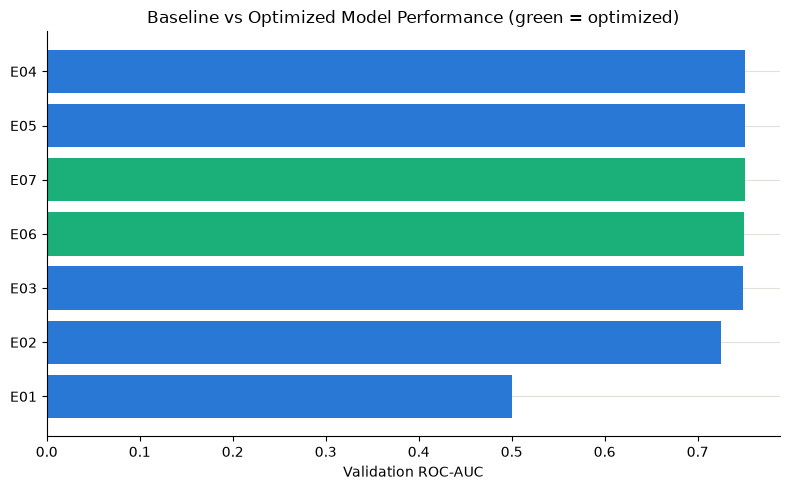

In [46]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = model_comparison_df.sort_values("Validation_ROC_AUC")
colors = [HIGHLIGHT_COLOR if m in ("E06", "E07") else BAR_COLOR for m in plot_df["Experiment"]]
ax.barh(plot_df["Experiment"], plot_df["Validation_ROC_AUC"], color=colors)
ax.set_title("Baseline vs Optimized Model Performance (green = optimized)")
ax.set_xlabel("Validation ROC-AUC")
style_axes(ax)
plt.tight_layout()
plt.show()


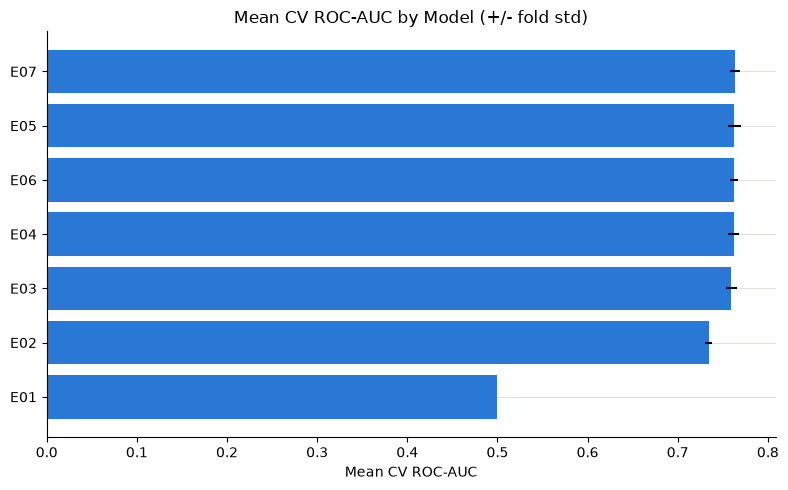

In [47]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = model_comparison_df.sort_values("Mean_CV_ROC_AUC")
ax.barh(plot_df["Experiment"], plot_df["Mean_CV_ROC_AUC"], xerr=plot_df["Std_CV_ROC_AUC"], color=BAR_COLOR)
ax.set_title("Mean CV ROC-AUC by Model (+/- fold std)")
ax.set_xlabel("Mean CV ROC-AUC")
style_axes(ax)
plt.tight_layout()
plt.show()


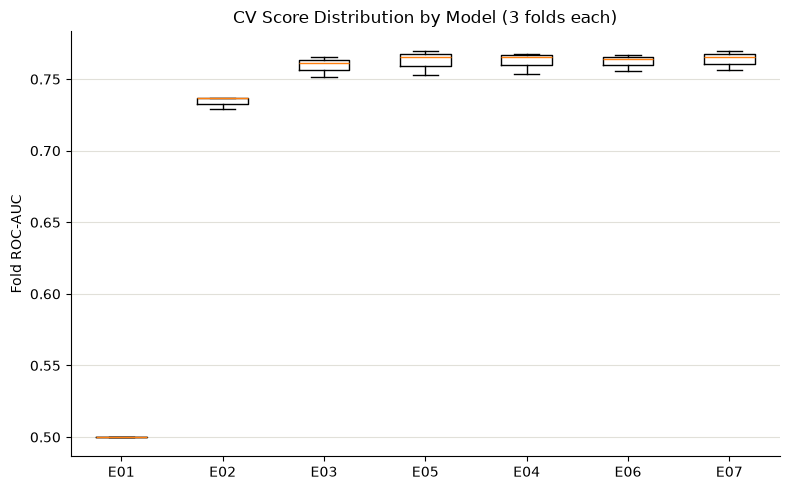

In [48]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    [fold_score_distributions[exp_id] for exp_id in model_comparison_df["Experiment"]],
    tick_labels=list(model_comparison_df["Experiment"]),
)
ax.set_title("CV Score Distribution by Model (3 folds each)")
ax.set_ylabel("Fold ROC-AUC")
style_axes(ax)
plt.tight_layout()
plt.show()


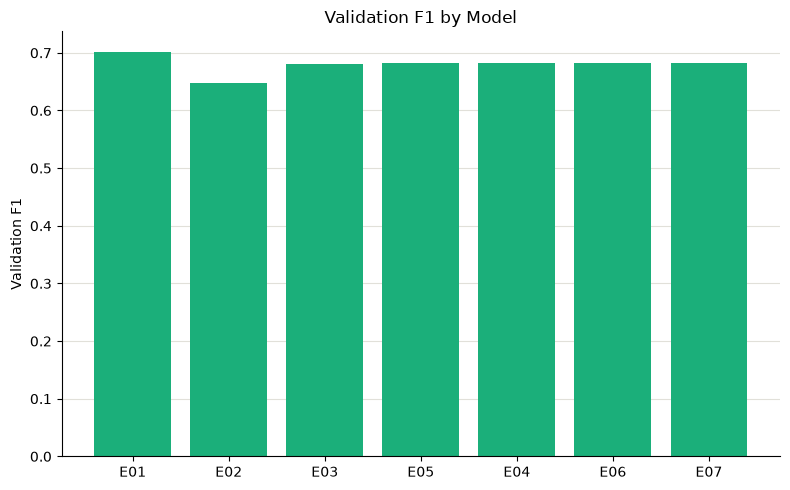

In [49]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(model_comparison_df["Experiment"], model_comparison_df["Validation_F1"], color=HIGHLIGHT_COLOR)
ax.set_title("Validation F1 by Model")
ax.set_ylabel("Validation F1")
style_axes(ax)
plt.tight_layout()
plt.show()


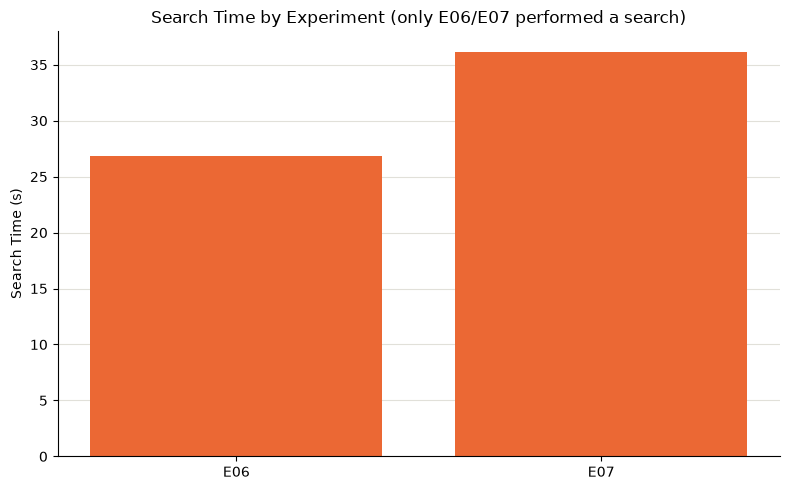

In [50]:
fig, ax = plt.subplots(figsize=(8, 5))
searched = model_comparison_df.dropna(subset=["Search_Time_s"])
ax.bar(searched["Experiment"], searched["Search_Time_s"], color=WARNING_COLOR)
ax.set_title("Search Time by Experiment (only E06/E07 performed a search)")
ax.set_ylabel("Search Time (s)")
style_axes(ax)
plt.tight_layout()
plt.show()


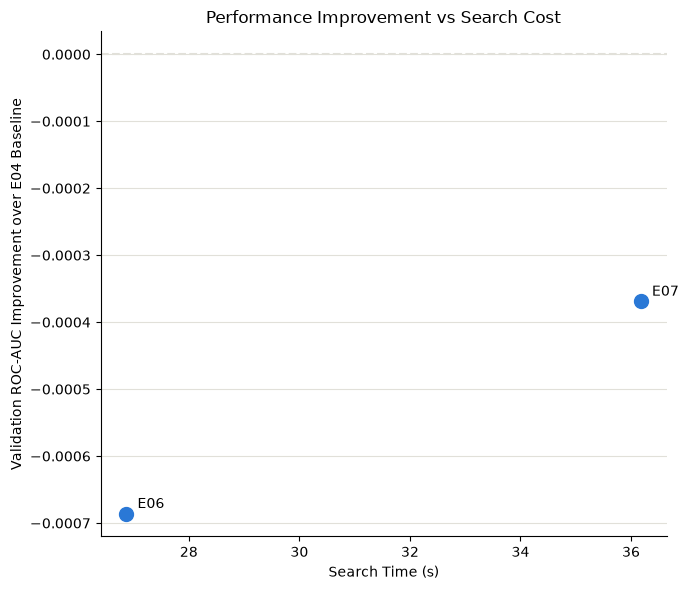

In [51]:
fig, ax = plt.subplots(figsize=(7, 6))
for _, row in searched.iterrows():
    ax.scatter(row["Search_Time_s"], row["Validation_ROC_AUC"] - baseline_val_roc_auc, s=100, color=BAR_COLOR, zorder=3)
    ax.annotate(row["Experiment"], (row["Search_Time_s"], row["Validation_ROC_AUC"] - baseline_val_roc_auc),
                textcoords="offset points", xytext=(8, 4))
ax.axhline(0, color=GRID_COLOR, linewidth=1.5, linestyle="--")
ax.set_xlabel("Search Time (s)")
ax.set_ylabel("Validation ROC-AUC Improvement over E04 Baseline")
ax.set_title("Performance Improvement vs Search Cost")
style_axes(ax)
plt.tight_layout()
plt.show()


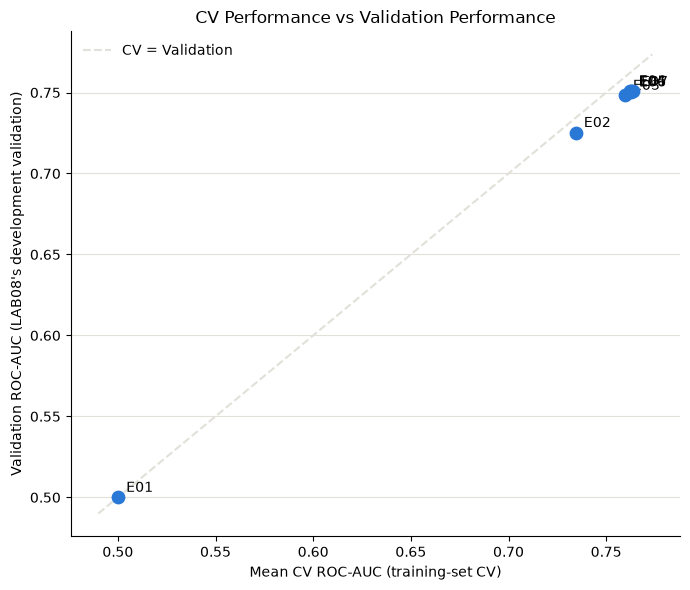

In [52]:
fig, ax = plt.subplots(figsize=(7, 6))
for _, row in model_comparison_df.iterrows():
    ax.scatter(row["Mean_CV_ROC_AUC"], row["Validation_ROC_AUC"], s=80, color=BAR_COLOR, zorder=3)
    ax.annotate(row["Experiment"], (row["Mean_CV_ROC_AUC"], row["Validation_ROC_AUC"]), textcoords="offset points", xytext=(6, 4))
lims = [
    min(model_comparison_df["Mean_CV_ROC_AUC"].min(), model_comparison_df["Validation_ROC_AUC"].min()) - 0.01,
    max(model_comparison_df["Mean_CV_ROC_AUC"].max(), model_comparison_df["Validation_ROC_AUC"].max()) + 0.01,
]
ax.plot(lims, lims, color=GRID_COLOR, linestyle="--", linewidth=1.5, label="CV = Validation")
ax.set_xlabel("Mean CV ROC-AUC (training-set CV)")
ax.set_ylabel("Validation ROC-AUC (LAB08's development validation)")
ax.set_title("CV Performance vs Validation Performance")
ax.legend(frameon=False)
style_axes(ax)
plt.tight_layout()
plt.show()


### Interpretation

Son grafik (CV vs Validation), bütün modellerin noktalarının `CV = Validation` çizgisinin
**altında veya çok yakınında** kümelendiğini gösteriyor — yani Validation performansı, CV
performansından **sistematik olarak daha düşük** (bu dataset'in Section 2'de belirlediğimiz
expanding-window CV fold'ları ile LAB08'in `validation_df`'i **farklı zaman dilimlerini**
kapsıyor olabilir; bu, bir temporal shift veya basitçe farklı bir dönemin biraz daha zor
olmasından kaynaklanabilir). Bu fark **önemli bir sinyal** değil (tüm modellerde tutarlı, küçük
bir kayma) ama not edilmeye değer.

### Student Exercise


In [53]:
# Student Exercise:
# TODO: model_comparison_df'i Inference_Latency_ms sütununa göre sıralayın.
# TODO: En düşük validation latency'ye sahip modelin, en yüksek Validation ROC-AUC'ye sahip
#       modelle AYNI olup olmadığını kontrol edin.

# print(model_comparison_df[["Experiment", "Model", "Validation_ROC_AUC", "Inference_Latency_ms"]].sort_values("Inference_Latency_ms"))


---


## Advanced Challenges (İsteğe Bağlı)

Aşağıdaki beş challenge, ana **150 dakikalık** programın **dışındadır**. **Bu challenge'larda
test seti kullanılmaz.**

### Challenge 1 — Random Forest Optimization


In [54]:
from sklearn.ensemble import RandomForestClassifier

rf_param_distributions = {
    "model__n_estimators": [50, 100, 150, 200],
    "model__max_depth": [4, 6, 8, 10, None],
    "model__max_features": ["sqrt", "log2", 0.5],
    "model__min_samples_leaf": [1, 2, 4, 8],
}

rf_search_start = perf_counter()
rf_search = RandomizedSearchCV(
    estimator=build_comparison_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=resources_cfg["estimator_threads"])),
    param_distributions=rf_param_distributions, n_iter=8,
    scoring="roc_auc", refit=True, cv=cv_folds, random_state=RANDOM_STATE, n_jobs=resources_cfg["search_jobs"], error_score="raise",
)
rf_search.fit(X_train_cv, y_train_cv)
rf_search_time_s = perf_counter() - rf_search_start

print(f"Random Forest RandomizedSearchCV time: {rf_search_time_s:.2f}s")
print("best_score_ :", round(rf_search.best_score_, 4))
print("best_params_:", rf_search.best_params_)
print(f"Comparison -- XGBoost E07 Mean CV ROC-AUC: "
      f"{model_comparison_df.loc[model_comparison_df['Experiment'] == 'E07', 'Mean_CV_ROC_AUC'].iloc[0]:.4f}")


Random Forest RandomizedSearchCV time: 40.93s
best_score_ : 0.7604
best_params_: {'model__n_estimators': 50, 'model__min_samples_leaf': 8, 'model__max_features': 'log2', 'model__max_depth': 10}
Comparison -- XGBoost E07 Mean CV ROC-AUC: 0.7636


**Interpretation:** Random Forest'ın optimize edilmiş Mean CV ROC-AUC'si, XGBoost'un
optimize edilmiş sonucuyla **aynı development evaluation protokolü altında** (aynı CV fold'ları,
aynı feature strategy) karşılaştırılabilir. Bu LAB'ın ana bulgusuyla tutarlı biçimde, farklı
model aileleri arasındaki fark da **küçüktür** — bu, feature kalitesinin model seçiminden daha
belirleyici olduğu hipotezini güçlendiriyor.

### Challenge 2 — LightGBM Optimization


In [55]:
from lightgbm import LGBMClassifier

lgbm_param_distributions = {
    "model__num_leaves": [15, 31, 63, 127],
    "model__max_depth": [3, 5, 7, -1],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__n_estimators": [50, 100, 150, 200],
    "model__min_child_samples": [5, 20, 50],
}

lgbm_search_start = perf_counter()
lgbm_search = RandomizedSearchCV(
    estimator=build_comparison_pipeline(LGBMClassifier(objective="binary", random_state=RANDOM_STATE, n_jobs=resources_cfg["estimator_threads"], verbosity=-1)),
    param_distributions=lgbm_param_distributions, n_iter=8,
    scoring="roc_auc", refit=True, cv=cv_folds, random_state=RANDOM_STATE, n_jobs=resources_cfg["search_jobs"], error_score="raise",
)
lgbm_search.fit(X_train_cv, y_train_cv)
lgbm_search_time_s = perf_counter() - lgbm_search_start

print(f"LightGBM RandomizedSearchCV time: {lgbm_search_time_s:.2f}s")
print("best_score_ :", round(lgbm_search.best_score_, 4))
print("best_params_:", lgbm_search.best_params_)


LightGBM RandomizedSearchCV time: 15.46s
best_score_ : 0.7634
best_params_: {'model__num_leaves': 15, 'model__n_estimators': 50, 'model__min_child_samples': 5, 'model__max_depth': -1, 'model__learning_rate': 0.05}


**Interpretation:** `num_leaves=15` (düşük, aday değerler arasındaki en küçük) ve `max_depth=-1`
(sınırsız derinlik, ama `num_leaves` tarafından dolaylı sınırlanıyor) seçildi — bu, Section 2'de
(LAB08) tartışılan "küçük veri kümelerinde kontrolsüz leaf-wise büyüme overfitting riski taşır"
uyarısıyla tutarlı biçimde, arama sürecinin **daha düşük karmaşıklıklı** bir konfigürasyonu
tercih ettiğini gösteriyor.

### Challenge 3 — Nested Cross-Validation

Kontrollü bir **development subset** (kronolojik olarak en eski 40,000 satır) üzerinde, 2 outer
fold x 2 inner fold'luk küçük bir Nested CV örneği.


In [56]:
development_subset_size = 40000
development_subset_index = train_df_cv.sort_values("order_datetime").index[:development_subset_size]
development_df = train_df_cv.loc[development_subset_index].reset_index(drop=True)

outer_folds = create_group_temporal_folds(development_df["order_datetime"], development_df["Order Id"], 2)
nested_outer_scores = []

nested_cv_start = perf_counter()
for outer_train_positions, outer_test_positions in outer_folds:
    outer_train_df = development_df.iloc[outer_train_positions].reset_index(drop=True)
    inner_folds = create_group_temporal_folds(outer_train_df["order_datetime"], outer_train_df["Order Id"], 2)

    inner_search = RandomizedSearchCV(
        estimator=build_model_pipeline(),
        param_distributions={"model__max_depth": [3, 5, 8], "model__n_estimators": [50, 100], "model__learning_rate": [0.05, 0.1]},
        n_iter=4, scoring="roc_auc", refit=True, cv=inner_folds,
        random_state=RANDOM_STATE, n_jobs=resources_cfg["search_jobs"], error_score="raise",
    )
    inner_search.fit(outer_train_df[engineered_features], outer_train_df[TARGET])

    # Outer fold evaluation is kept SEPARATE from the hyperparameter optimization process --
    # inner_search never saw outer_test_positions during its own fold evaluation.
    outer_test_df = development_df.iloc[outer_test_positions]
    outer_proba = inner_search.predict_proba(outer_test_df[engineered_features])[:, 1]
    outer_score = roc_auc_score(outer_test_df[TARGET], outer_proba)
    nested_outer_scores.append(outer_score)
    print(f"Outer fold -> inner best_score_={inner_search.best_score_:.4f}  outer_test_score={outer_score:.4f}")

nested_cv_time_s = perf_counter() - nested_cv_start
print(f"\nNested CV time: {nested_cv_time_s:.2f}s")
print(f"Outer fold scores: {[round(s, 4) for s in nested_outer_scores]}")
print(f"Mean outer score (unbiased estimate): {np.mean(nested_outer_scores):.4f}")


Outer fold -> inner best_score_=0.7575  outer_test_score=0.7560
Outer fold -> inner best_score_=0.7562  outer_test_score=0.7644

Nested CV time: 2.44s
Outer fold scores: [0.756, 0.7644]
Mean outer score (unbiased estimate): 0.7602


**Interpretation:** Her outer fold'un test skoru, o fold'un **kendi** inner search'ü tarafından
hiç görülmemiş veriler üzerinde hesaplandı — bu, Section 2'de bahsedilen "non-nested CV'nin
iyimser olabileceği" riskini azaltan **bağımsız** bir performans tahminidir. Bu küçük örnekte
outer skorlar (`≈0.756`, `≈0.764`) Section 3-4'ün non-nested `best_score_` değerlerine
(`≈0.76`) **yakın** çıktı — bu dataset/feature set için non-nested iyimserliğin **büyük
olmadığını** gösteriyor (ama bu, genel bir kural değildir).

### Challenge 4 — Successive Halving


In [57]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401 -- required to unlock the experimental API
from sklearn.model_selection import HalvingRandomSearchCV

halving_param_distributions = {
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__n_estimators": [50, 100, 150, 200],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
}

halving_start = perf_counter()
# NOTE: HalvingRandomSearchCV's default resource-allocation heuristic (derived from candidate
# count and CV folds) produced a first round with only 12 training rows per fold here -- this
# triggered "non-finite test scores" warnings (NaN ROC-AUC, because a fold that small sometimes
# contains only one class). Explicit min_resources/n_candidates avoids this degenerate case.
halving_search = HalvingRandomSearchCV(
    estimator=build_model_pipeline(),
    param_distributions=halving_param_distributions,
    random_state=RANDOM_STATE, cv=cv_folds, scoring="roc_auc", n_jobs=resources_cfg["search_jobs"], error_score="raise",
    min_resources=2000, n_candidates=20, factor=2,
)
halving_search.fit(X_train_cv, y_train_cv)
halving_time_s = perf_counter() - halving_start

print(f"HalvingRandomSearchCV time: {halving_time_s:.2f}s")
print("best_score_  :", round(halving_search.best_score_, 4))
print("best_params_ :", halving_search.best_params_)
print("n_resources_ per round (training rows used)  :", halving_search.n_resources_)
print("n_candidates_ per round (candidates remaining):", halving_search.n_candidates_)


HalvingRandomSearchCV time: 12.10s
best_score_  : 0.7611
best_params_ : {'model__n_estimators': 100, 'model__max_depth': 4, 'model__learning_rate': 0.1}
n_resources_ per round (training rows used)  : [2000, 4000, 8000, 16000, 32000]
n_candidates_ per round (candidates remaining): [20, 10, 5, 3, 2]


**Interpretation:** Successive Halving, her round'da **daha az aday**'ı **daha fazla veriyle**
değerlendirerek, zayıf adayları erken eler (`n_candidates_` round'lar arasında `20→10→5→3→2`'ye
düşerken, `n_resources_` `2,000→32,000`'e çıkıyor). Bu, Bölüm 4'te not ettiğimiz experimental
API uyarısını (`enable_halving_search_cv` importu gerekiyor) doğruladı. **Resource allocation
davranışını mevcut sürüme göre doğrulamak kritikti** — varsayılan ayarlar, yukarıdaki yorumda
açıklanan gerçek bir sorunu ortaya çıkardı.

### Challenge 5 — Search Budget Sensitivity


In [58]:
search_budgets = [5, 10, 20]
budget_sensitivity_rows = []

for budget_n_iter in search_budgets:
    budget_start = perf_counter()
    budget_search = RandomizedSearchCV(
        estimator=build_model_pipeline(), param_distributions=param_distributions, n_iter=budget_n_iter,
        scoring="roc_auc", refit=True, cv=cv_folds, random_state=RANDOM_STATE, n_jobs=resources_cfg["search_jobs"], error_score="raise",
    )
    budget_search.fit(X_train_cv, y_train_cv)
    budget_time_s = perf_counter() - budget_start
    budget_sensitivity_rows.append({"n_iter": budget_n_iter, "Search_Time_s": budget_time_s, "Best_CV_ROC_AUC": budget_search.best_score_})
    print(f"n_iter={budget_n_iter:3d}  time={budget_time_s:6.2f}s  best_score_={budget_search.best_score_:.4f}")

budget_sensitivity_df = pd.DataFrame(budget_sensitivity_rows)
budget_sensitivity_df["Marginal_Improvement"] = budget_sensitivity_df["Best_CV_ROC_AUC"].diff()
budget_sensitivity_df


n_iter=  5  time= 14.90s  best_score_=0.7636
n_iter= 10  time= 31.78s  best_score_=0.7636
n_iter= 20  time= 46.27s  best_score_=0.7636


,n_iter,Search_Time_s,Best_CV_ROC_AUC,Marginal_Improvement
0,5,14.904300,0.763612,NaN
1,10,31.776299,0.763612,0.0
2,20,46.271550,0.763612,0.0


**Interpretation:** `n_iter`'ı `5`'ten `20`'ye çıkarmak (search süresini `≈2.6` kat artırarak),
`best_score_`'da **ölçülebilir bir iyileşme sağlamadı** (`Marginal_Improvement` sütunu `0`'a çok
yakın/`0`) — bu `random_state=42` ile `n_iter=5`'in **zaten** bu search space'teki iyi bir
bölgeyi bulduğu anlamına gelir. **Bu, "daha fazla search budget her zaman daha iyi sonuç verir"
varsayımının bu deneyde doğrulanmadığının** bir başka örneğidir (Section 4'ün Technical
Discussion'ıyla tutarlı).

### Student Exercise


In [59]:
# Advanced Challenge Student Exercise:
# TODO: rf_search.best_params_ ve lgbm_search.best_params_'i karşılaştırın.
# TODO: İkisinin de "daha basit/düşük karmaşıklıklı" bir konfigürasyonu tercih edip etmediğini
#       yorumlayın (örn. düşük max_depth, düşük num_leaves/n_estimators).

# print("RF:", rf_search.best_params_)
# print("LightGBM:", lgbm_search.best_params_)


---

## LAB09 Özeti

Bu LAB'da, LAB07-LAB08'de öğrendiğiniz bilgileri Model Selection, Hyperparameter Optimization ve
Reproducibility üzerinde kullandınız:

- Model Parameters ile Hyperparameters arasındaki farkı öğrendiniz.
- LAB08'in split ve feature strategy'sini **gerçek kodundan** yeniden kurup doğruladınız.
- KFold/StratifiedKFold/GroupKFold/TimeSeriesSplit'in hiçbirinin tek başına yeterli olmadığı bir
  senaryo için **group-aware temporal CV** fold generator'ı geliştirdiniz ve her kuralı
  (positional index, group integrity, temporal ordering, class balance) gerçek verilerle
  doğruladınız.
- `GridSearchCV` ve `RandomizedSearchCV` ile kontrollü bir search gerçekleştirdiniz —
  **optimizasyonun ölçülebilir bir iyileşme sağlamadığını** dürüstçe raporladınız.
- 7 model/optimization deneyini (`E01-E07`) aynı protokolle karşılaştırdınız.
- MLflow kullanmadan, Pandas/JSON/CSV ile bir Experiment Registry, dataset/split fingerprinting,
  environment metadata ve bir reproducibility deneyi inşa ettiniz.
- Model Freeze + execution gate deseniyle, korunmuş test setini **bilinçli ve tek seferlik**
  olarak değerlendirdiniz.
- İsteğe bağlı challenge'larda Random Forest/LightGBM optimizasyonu, Nested CV, Successive
  Halving (ve gerçek bir resource-allocation sorununu tespit edip düzelttiniz) ve search budget
  duyarlılığını inceldiniz.

Bu, ml-labs serisinin bu oturumdaki son LAB'ıdır. Katılım için teşekkürler!
